In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/twincheck")

print("Project exists:", ROOT.exists())

# Check important F2 files
files_to_check = [
    "data/processed/vision/verite.jsonl",
    "features/vision/verite/clip_vit_l14/verified_image_extraction/verite_clip_vit_l14_image_projected_embeddings.npy",
    "features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings.npy",
]

for relative_path in files_to_check:
    path = ROOT / relative_path
    print(f"\n{relative_path}")
    print("Exists:", path.exists())
    if path.exists():
        print("Size (MB):", round(path.stat().st_size / (1024**2), 2))

Project exists: True

data/processed/vision/verite.jsonl
Exists: True
Size (MB): 0.31

features/vision/verite/clip_vit_l14/verified_image_extraction/verite_clip_vit_l14_image_projected_embeddings.npy
Exists: True
Size (MB): 1.94

features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings.npy
Exists: True
Size (MB): 2.91


In [3]:
import json

verite_path = ROOT / "data/processed/vision/verite.jsonl"

with open(verite_path, "r", encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

print("Total records:", len(records))
print("\nFirst 3 records:\n")

for record in records[:3]:
    print(json.dumps(record, indent=2, ensure_ascii=False))
    print("-" * 80)

Total records: 1001

First 3 records:

{
  "caption": "Photograph shows a family that was taken away by local epidemic prevention personnel after they had returned home from Hubei Province in February 2020 while they were asked to self-quarantine in their homes for 14 days.",
  "image_path": "images/true_0.jpg",
  "resolved_image_path": "/content/drive/MyDrive/twincheck/data/raw/verite/images_download/extracted/images/true_0.jpg",
  "label": "true"
}
--------------------------------------------------------------------------------
{
  "caption": "Photograph shows Chinese officials in white protective hazmat suits carrying people down a hallway to be quarantined for having COVID-19 in November 2022.",
  "image_path": "images/true_0.jpg",
  "resolved_image_path": "/content/drive/MyDrive/twincheck/data/raw/verite/images_download/extracted/images/true_0.jpg",
  "label": "miscaptioned"
}
--------------------------------------------------------------------------------
{
  "caption": "Photogra

In [4]:
from collections import Counter

label_counts = Counter(record["label"] for record in records)

print("Label distribution:")
for label, count in label_counts.items():
    print(f"{label}: {count}")

print("\nUnique image paths:", len(set(r["image_path"] for r in records)))
print("Total records:", len(records))

Label distribution:
true: 338
miscaptioned: 338
out-of-context: 325

Unique image paths: 663
Total records: 1001


In [5]:
from collections import defaultdict
import numpy as np

# Group records by image path
image_labels = defaultdict(set)

for r in records:
    image_labels[r["image_path"]].add(r["label"])

conflicting_images = {
    image: labels
    for image, labels in image_labels.items()
    if len(labels) > 1
}

print("Unique images:", len(image_labels))
print("Images with multiple labels:", len(conflicting_images))

# Load embeddings
clip_path = ROOT / "features/vision/verite/clip_vit_l14/verified_image_extraction/verite_clip_vit_l14_image_projected_embeddings.npy"
siglip_path = ROOT / "features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings.npy"

clip_embeddings = np.load(clip_path)
siglip_embeddings = np.load(siglip_path)

print("\nCLIP shape:", clip_embeddings.shape)
print("SigLIP shape:", siglip_embeddings.shape)
print("Records:", len(records))

Unique images: 663
Images with multiple labels: 338

CLIP shape: (663, 768)
SigLIP shape: (663, 1152)
Records: 1001


In [6]:
vision_data = ROOT / "data" / "processed" / "vision"

for folder in vision_data.iterdir():
    if folder.is_dir():
        print("\nDataset:", folder.name)
        print("Files:", [f.name for f in folder.iterdir()][:10])


Dataset: splits
Files: ['train.csv', 'validation.csv', 'test.csv']

Dataset: genimage
Files: ['train', 'validation']

Dataset: m4fc_images
Files: ['m4fc_000301.jpg', 'm4fc_000576.jpg', 'm4fc_000617.jpg', 'm4fc_000165.jpg', 'm4fc_000172.jpg', 'm4fc_000000.jpg', 'm4fc_000232.jpg', 'm4fc_000444.jpg', 'm4fc_000428.jpg', 'm4fc_000452.jpg']

Dataset: m4fc
Files: ['m4fc_image_availability_audit.csv', 'm4fc_available_603_image_manifest.csv', 'm4fc_missing_11_image_records.csv']


In [7]:
from pathlib import Path

genimage_root = ROOT / "data" / "processed" / "vision" / "genimage"

for split in ["train", "validation"]:
    split_path = genimage_root / split

    print(f"\n--- {split.upper()} ---")

    for folder in split_path.iterdir():
        if folder.is_dir():
            count = sum(1 for f in folder.iterdir() if f.is_file())
            print(f"{folder.name}: {count} files")


--- TRAIN ---
real: 5000 files
fake: 0 files

--- VALIDATION ---
real: 1000 files
fake: 0 files


In [8]:
from pathlib import Path

genimage_root = ROOT / "data" / "processed" / "vision" / "genimage"

for path in genimage_root.rglob("*"):
    if path.is_dir():
        files = [f for f in path.iterdir() if f.is_file()]
        if files:
            print(f"{path.relative_to(genimage_root)}: {len(files)} files")
            print("  Examples:", [f.name for f in files[:3]])

train/real: 5000 files
  Examples: ['15228867ac6a51b6435fc50a9cfdac66.JPEG', '3192356344c5e1536508d696f2327db2.JPEG', 'b9612363ffe6983dc66b4626278af782.JPEG']
validation/real: 1000 files
  Examples: ['758644bbd327df20e4fa39c9c76b6953.JPEG', '0d5aaf636728309bf86cfd0b7421ae22.JPEG', '6c6017bdcaf133ea271256712188f3ab.JPEG']
validation/fake/BigGAN: 1000 files
  Examples: ['1c923109974161d21b114ccacc1e1507.png', '3415154784d53d7717c5b5ca634d6809.png', 'c63233f50bc7e7f39b2a8425e5b17acb.png']
validation/fake/Stable_Diffusion_v1_4: 1000 files
  Examples: ['4bae42873f57c2ff200a0f4bc76e1ae1.png', 'd118c153021745dfe2815028ca14032b.png', 'a278d5779cbefa9076a8b6af0103e5d0.png']
train/fake/BigGAN: 5000 files
  Examples: ['c0303c0491ab1e463e11b387e98bc42f.png', 'ff7aa33fd07fe78102bf4d0eb54d57d8.png', '348121be633ecedbf9af343c223636a3.png']
train/fake/Stable_Diffusion_v1_4: 5000 files
  Examples: ['fbcbba9505b9b6532033ef08e6c427ce.png', '017b2054e8cb9fc99486b75a2d9904eb.png', '9657a646dc8265465b7dedee

In [9]:
for split in ["train", "validation", "test"]:
    split_path = genimage_root / split

    print(f"\n--- {split.upper()} ---")

    if not split_path.exists():
        print("Folder does not exist")
        continue

    for folder in split_path.iterdir():
        if folder.is_dir():
            count = sum(1 for f in folder.iterdir() if f.is_file())
            print(f"{folder.name}: {count} files")


--- TRAIN ---
real: 5000 files
fake: 0 files

--- VALIDATION ---
real: 1000 files
fake: 0 files

--- TEST ---
Folder does not exist


In [10]:
from pathlib import Path
from PIL import Image

ROOT = Path("/content/drive/MyDrive/twincheck")
DATA_DIR = ROOT / "data/processed/vision/genimage"

folders = [
    DATA_DIR / "train/real",
    DATA_DIR / "train/fake",
    DATA_DIR / "validation/real",
    DATA_DIR / "validation/fake",
]

for folder in folders:
    images = list(folder.rglob("*"))
    images = [p for p in images if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]

    readable = 0
    corrupted = []

    for img_path in images[:20]:  # Test only 20 images per folder
        try:
            with Image.open(img_path) as img:
                img.verify()
            readable += 1
        except Exception:
            corrupted.append(img_path.name)

    print(f"\nFolder: {folder}")
    print(f"Images found: {len(images)}")
    print(f"Readable in sample: {readable}/20")
    print(f"Corrupted in sample: {len(corrupted)}")


Folder: /content/drive/MyDrive/twincheck/data/processed/vision/genimage/train/real
Images found: 5000
Readable in sample: 20/20
Corrupted in sample: 0

Folder: /content/drive/MyDrive/twincheck/data/processed/vision/genimage/train/fake
Images found: 10000
Readable in sample: 20/20
Corrupted in sample: 0

Folder: /content/drive/MyDrive/twincheck/data/processed/vision/genimage/validation/real
Images found: 1000
Readable in sample: 20/20
Corrupted in sample: 0

Folder: /content/drive/MyDrive/twincheck/data/processed/vision/genimage/validation/fake
Images found: 2000
Readable in sample: 20/20
Corrupted in sample: 0


In [11]:
from collections import Counter

for split in ["train", "validation"]:
    fake_dir = DATA_DIR / split / "fake"

    generator_counts = Counter()

    for img_path in fake_dir.rglob("*"):
        if img_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            generator = img_path.parent.name
            generator_counts[generator] += 1

    print(f"\n{'='*40}")
    print(f"{split.upper()} FAKE IMAGE DISTRIBUTION")
    print(f"{'='*40}")

    for generator, count in generator_counts.items():
        print(f"{generator}: {count}")


TRAIN FAKE IMAGE DISTRIBUTION
BigGAN: 5000
Stable_Diffusion_v1_4: 5000

VALIDATION FAKE IMAGE DISTRIBUTION
BigGAN: 1000
Stable_Diffusion_v1_4: 1000


In [12]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/twincheck")
GENIMAGE = ROOT / "data/processed/vision/genimage"

folders = {
    "Train Real": GENIMAGE / "train/real",
    "Train BigGAN": GENIMAGE / "train/fake/BigGAN",
    "Train SD v1.4": GENIMAGE / "train/fake/Stable_Diffusion_v1_4",
    "Validation Real": GENIMAGE / "validation/real",
    "Validation BigGAN": GENIMAGE / "validation/fake/BigGAN",
    "Validation SD v1.4": GENIMAGE / "validation/fake/Stable_Diffusion_v1_4",
}

for name, folder in folders.items():
    if folder.exists():
        count = sum(1 for f in folder.rglob("*") if f.is_file())
        print(f"{name:25s}: {count:5d} images | {folder}")
    else:
        print(f"{name:25s}: MISSING | {folder}")

Train Real               :  5000 images | /content/drive/MyDrive/twincheck/data/processed/vision/genimage/train/real
Train BigGAN             :  5000 images | /content/drive/MyDrive/twincheck/data/processed/vision/genimage/train/fake/BigGAN
Train SD v1.4            :  5000 images | /content/drive/MyDrive/twincheck/data/processed/vision/genimage/train/fake/Stable_Diffusion_v1_4
Validation Real          :  1000 images | /content/drive/MyDrive/twincheck/data/processed/vision/genimage/validation/real
Validation BigGAN        :  1000 images | /content/drive/MyDrive/twincheck/data/processed/vision/genimage/validation/fake/BigGAN
Validation SD v1.4       :  1000 images | /content/drive/MyDrive/twincheck/data/processed/vision/genimage/validation/fake/Stable_Diffusion_v1_4


In [13]:
from pathlib import Path
import random
import pandas as pd

ROOT = Path("/content/drive/MyDrive/twincheck")
GENIMAGE = ROOT / "data/processed/vision/genimage"

SEED = 42
random.seed(SEED)

def get_images(folder):
    extensions = {".jpg", ".jpeg", ".png", ".webp"}
    return sorted([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ])

# Collect images
train_real = get_images(GENIMAGE / "train/real")
train_biggan = get_images(GENIMAGE / "train/fake/BigGAN")

val_real = get_images(GENIMAGE / "validation/real")
val_biggan = get_images(GENIMAGE / "validation/fake/BigGAN")
val_sd = get_images(GENIMAGE / "validation/fake/Stable_Diffusion_v1_4")

# Reserve 1,000 real images for the unseen-generator test
random.shuffle(train_real)

test_real = train_real[:1000]
remaining_real = train_real[1000:]

# Construct manifest
records = []

def add_images(images, split, label, generator):
    for img in images:
        records.append({
            "image_path": str(img),
            "split": split,
            "label": label,
            "generator": generator
        })

# Training
add_images(remaining_real, "train", 0, "real")
add_images(train_biggan, "train", 1, "BigGAN")

# Validation
add_images(val_real, "validation", 0, "real")
add_images(val_biggan, "validation", 1, "BigGAN")

# Unseen-generator test
add_images(test_real, "test", 0, "real")
add_images(val_sd, "test", 1, "Stable_Diffusion_v1_4")

# Save manifest
manifest = pd.DataFrame(records)

output_path = ROOT / "data/processed/vision/f3_authenticity_manifest.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

manifest.to_csv(output_path, index=False)

print("Manifest created successfully!")
print("Saved to:", output_path)
print("\nSplit distribution:")
print(manifest.groupby(["split", "generator", "label"]).size())

print("\nTotal records:", len(manifest))
print("\nFirst 5 rows:")
display(manifest.head())

Manifest created successfully!
Saved to: /content/drive/MyDrive/twincheck/data/processed/vision/f3_authenticity_manifest.csv

Split distribution:
split       generator              label
test        Stable_Diffusion_v1_4  1        1000
            real                   0        1000
train       BigGAN                 1        5000
            real                   0        4000
validation  BigGAN                 1        1000
            real                   0        1000
dtype: int64

Total records: 13000

First 5 rows:


,image_path,split,label,generator
0,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
1,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
2,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
3,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
4,/content/drive/MyDrive/twincheck/data/processe...,train,0,real


In [14]:
import pandas as pd
from pathlib import Path

manifest_path = ROOT / "data/processed/vision/f3_authenticity_manifest.csv"
manifest = pd.read_csv(manifest_path)

# 1. Check duplicate paths
duplicate_paths = manifest["image_path"].duplicated().sum()

# 2. Check whether files exist
missing_files = [
    p for p in manifest["image_path"]
    if not Path(p).exists()
]

# 3. Check if any path appears in multiple splits
split_counts = manifest.groupby("image_path")["split"].nunique()
cross_split_leakage = (split_counts > 1).sum()

# 4. Check labels and generator assignments
invalid_labels = manifest[
    ~manifest["label"].isin([0, 1])
]

print("=== LEAKAGE & INTEGRITY CHECK ===")
print("Total records:", len(manifest))
print("Duplicate paths:", duplicate_paths)
print("Missing files:", len(missing_files))
print("Paths appearing across multiple splits:", cross_split_leakage)
print("Invalid labels:", len(invalid_labels))

if missing_files:
    print("\nFirst missing files:")
    print(missing_files[:10])

print("\n=== SPLIT SUMMARY ===")
print(manifest.groupby(["split", "generator", "label"]).size())

if (
    duplicate_paths == 0
    and len(missing_files) == 0
    and cross_split_leakage == 0
    and len(invalid_labels) == 0
):
    print("\nPASS: Basic manifest integrity checks passed.")
else:
    print("\nWARNING: Issues found. Do not proceed to training yet.")

=== LEAKAGE & INTEGRITY CHECK ===
Total records: 13000
Duplicate paths: 0
Missing files: 0
Paths appearing across multiple splits: 0
Invalid labels: 0

=== SPLIT SUMMARY ===
split       generator              label
test        Stable_Diffusion_v1_4  1        1000
            real                   0        1000
train       BigGAN                 1        5000
            real                   0        4000
validation  BigGAN                 1        1000
            real                   0        1000
dtype: int64

PASS: Basic manifest integrity checks passed.


In [16]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("Running on CPU")

try:
    import transformers
    print("Transformers version:", transformers.__version__)
except ImportError:
    print("Transformers is not installed")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: NVIDIA L4
GPU memory: 22.03 GB
Transformers version: 5.22.1


In [17]:
from transformers import CLIPModel, CLIPProcessor
import torch

MODEL_NAME = "openai/clip-vit-large-patch14"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading CLIP ViT-L/14...")

processor = CLIPProcessor.from_pretrained(MODEL_NAME)
clip_model = CLIPModel.from_pretrained(MODEL_NAME)

clip_model = clip_model.to(device)
clip_model.eval()

print("\n=== Model Loaded ===")
print("Model:", MODEL_NAME)
print("Device:", device)
print("Vision embedding dimension:",
      clip_model.config.projection_dim)
print("Model in evaluation mode:", not clip_model.training)

Loading CLIP ViT-L/14...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]


=== Model Loaded ===
Model: openai/clip-vit-large-patch14
Device: cuda
Vision embedding dimension: 768
Model in evaluation mode: True


In [ ]:
from pathlib import Path

vision_dir = ROOT / "data/processed/vision"

for path in sorted(vision_dir.rglob("*")):
    if path.is_dir():
        print(path.relative_to(ROOT))
    else:
        print(path.relative_to(ROOT))

In [21]:
import numpy as np
import pandas as pd
from pathlib import Path

FEATURE_DIR = Path("/content/drive/MyDrive/twincheck/features/vision/genimage")

clip_path = FEATURE_DIR / "genimage_clip_vit_l14_image_projected_embeddings.npy"
embedding_manifest_path = FEATURE_DIR / "genimage_image_embedding_manifest.csv"

clip_embeddings = np.load(clip_path, mmap_mode="r")
embedding_manifest = pd.read_csv(embedding_manifest_path)

print("CLIP embedding shape:", clip_embeddings.shape)
print("CLIP embedding dtype:", clip_embeddings.dtype)

print("\nEmbedding manifest shape:", embedding_manifest.shape)
print("Manifest columns:")
print(embedding_manifest.columns.tolist())

print("\nFirst 5 manifest rows:")
display(embedding_manifest.head())

print("\nF3 manifest columns:")
f3_manifest = pd.read_csv(ROOT / "data/processed/vision/f3_authenticity_manifest.csv")
print(f3_manifest.columns.tolist())
display(f3_manifest.head())

CLIP embedding shape: (18000, 768)
CLIP embedding dtype: float32

Embedding manifest shape: (18000, 5)
Manifest columns:
['image_id', 'image_path', 'split', 'class_name', 'generator']

First 5 manifest rows:


,image_id,image_path,split,class_name,generator
0,5f827c5cd33aeba78f7744f4930d37c9,/content/drive/MyDrive/twincheck/data/processe...,train,real,real
1,e34b83d69e71dd7d46e0d3818556b24f,/content/drive/MyDrive/twincheck/data/processe...,train,real,real
2,6ff5466026b08f2401c619422e6c9da5,/content/drive/MyDrive/twincheck/data/processe...,train,real,real
3,f3dfc3d5f0c862544d97289d5f590ef5,/content/drive/MyDrive/twincheck/data/processe...,train,real,real
4,beb5358daab19f4e613804bed96bc1cf,/content/drive/MyDrive/twincheck/data/processe...,train,real,real



F3 manifest columns:
['image_path', 'split', 'label', 'generator']


,image_path,split,label,generator
0,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
1,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
2,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
3,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
4,/content/drive/MyDrive/twincheck/data/processe...,train,0,real


In [22]:
import pandas as pd

# Load F3 manifest
f3_manifest = pd.read_csv(
    ROOT / "data/processed/vision/f3_authenticity_manifest.csv"
)

# Compare image paths
embedding_paths = set(embedding_manifest["image_path"])
f3_paths = set(f3_manifest["image_path"])

matched_paths = embedding_paths.intersection(f3_paths)
missing_paths = f3_paths - embedding_paths

print("=" * 50)
print("EMBEDDING COVERAGE CHECK")
print("=" * 50)

print("Total F3 images:", len(f3_manifest))
print("Total existing embeddings:", len(embedding_manifest))
print("F3 images found in embeddings:", len(matched_paths))
print("F3 images missing embeddings:", len(missing_paths))

print("\nCoverage percentage:",
      round(len(matched_paths) / len(f3_paths) * 100, 2), "%")

print("\nMissing image examples:")
for path in list(missing_paths)[:5]:
    print(path)

print("\nF3 split distribution:")
print(f3_manifest["split"].value_counts())

print("\nF3 generator distribution:")
print(f3_manifest["generator"].value_counts())

EMBEDDING COVERAGE CHECK
Total F3 images: 13000
Total existing embeddings: 18000
F3 images found in embeddings: 13000
F3 images missing embeddings: 0

Coverage percentage: 100.0 %

Missing image examples:

F3 split distribution:
split
train         9000
validation    2000
test          2000
Name: count, dtype: int64

F3 generator distribution:
generator
real                     6000
BigGAN                   6000
Stable_Diffusion_v1_4    1000
Name: count, dtype: int64


In [23]:
import numpy as np
import pandas as pd

# Map each image path to its row in the existing embedding matrix
embedding_path_to_index = {
    path: idx
    for idx, path in enumerate(embedding_manifest["image_path"])
}

# Obtain embedding indices in exactly the F3 manifest order
f3_embedding_indices = f3_manifest["image_path"].map(
    embedding_path_to_index
).to_numpy()

# Extract and align embeddings
X_f3 = clip_embeddings[f3_embedding_indices]

# Extract labels
y_f3 = f3_manifest["label"].to_numpy()

# Verify alignment
assert len(X_f3) == len(f3_manifest)
assert len(y_f3) == len(f3_manifest)
assert not pd.isna(f3_embedding_indices).any()

print("F3 feature matrix shape:", X_f3.shape)
print("F3 labels shape:", y_f3.shape)
print("Feature dtype:", X_f3.dtype)

print("\nLabel distribution:")
print(pd.Series(y_f3).value_counts().sort_index())

print("\nSplit-wise distribution:")
display(pd.crosstab(f3_manifest["split"], f3_manifest["label"]))

print("\nAlignment verification: PASSED")

F3 feature matrix shape: (13000, 768)
F3 labels shape: (13000,)
Feature dtype: float32

Label distribution:
0    6000
1    7000
Name: count, dtype: int64

Split-wise distribution:


label,0,1
split,,
test,1000,1000
train,4000,5000
validation,1000,1000



Alignment verification: PASSED


In [24]:
# Identify samples belonging to each split
train_idx = f3_manifest["split"].to_numpy() == "train"
val_idx = f3_manifest["split"].to_numpy() == "validation"
test_idx = f3_manifest["split"].to_numpy() == "test"

# Split the aligned feature matrix
X_train = X_f3[train_idx]
X_val = X_f3[val_idx]
X_test = X_f3[test_idx]

# Split labels
y_train = y_f3[train_idx]
y_val = y_f3[val_idx]
y_test = y_f3[test_idx]

# Verify
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

assert X_train.shape[0] == 9000
assert X_val.shape[0] == 2000
assert X_test.shape[0] == 2000

print("\nDataset splitting: PASSED")

Train: (9000, 768) (9000,)
Validation: (2000, 768) (2000,)
Test: (2000, 768) (2000,)

Dataset splitting: PASSED


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Train Logistic Regression
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_model.fit(X_train, y_train)

# Validation predictions
y_val_pred = lr_model.predict(X_val)

# Evaluation
print("LOGISTIC REGRESSION — VALIDATION RESULTS")
print("=" * 45)

print("Accuracy :", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred), 4))
print("Recall   :", round(recall_score(y_val, y_val_pred), 4))
print("F1-score :", round(f1_score(y_val, y_val_pred), 4))

LOGISTIC REGRESSION — VALIDATION RESULTS
Accuracy : 0.9995
Precision: 0.999
Recall   : 1.0
F1-score : 0.9995


In [26]:
from sklearn.metrics import confusion_matrix, classification_report

# Confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Real", "AI-generated"],
    digits=4
))

# Find misclassified validation images
misclassified_idx = np.where(y_val != y_val_pred)[0]

print("\nNumber of misclassified images:", len(misclassified_idx))

# Display misclassified samples
if len(misclassified_idx) > 0:
    val_manifest = f3_manifest[val_idx].reset_index(drop=True)

    errors = val_manifest.iloc[misclassified_idx].copy()
    errors["true_label"] = y_val[misclassified_idx]
    errors["predicted_label"] = y_val_pred[misclassified_idx]

    display(errors)
else:
    print("No validation misclassifications.")

Confusion Matrix:
[[ 999    1]
 [   0 1000]]

Classification Report:
              precision    recall  f1-score   support

        Real     1.0000    0.9990    0.9995      1000
AI-generated     0.9990    1.0000    0.9995      1000

    accuracy                         0.9995      2000
   macro avg     0.9995    0.9995    0.9995      2000
weighted avg     0.9995    0.9995    0.9995      2000


Number of misclassified images: 1


,image_path,split,label,generator,true_label,predicted_label
358,/content/drive/MyDrive/twincheck/data/processe...,validation,0,real,0,1


In [27]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Train Linear SVM
svm_model = LinearSVC(
    C=1.0,
    max_iter=10000,
    random_state=42
)

svm_model.fit(X_train, y_train)

# Validation predictions
y_val_svm_pred = svm_model.predict(X_val)

# Metrics
print("LINEAR SVM — VALIDATION RESULTS")
print("=" * 45)

print("Accuracy :", round(accuracy_score(y_val, y_val_svm_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_svm_pred), 4))
print("Recall   :", round(recall_score(y_val, y_val_svm_pred), 4))
print("F1-score :", round(f1_score(y_val, y_val_svm_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_svm_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_svm_pred,
    target_names=["Real", "AI-generated"],
    digits=4
))

LINEAR SVM — VALIDATION RESULTS
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Confusion Matrix:
[[1000    0]
 [   0 1000]]

Classification Report:
              precision    recall  f1-score   support

        Real     1.0000    1.0000    1.0000      1000
AI-generated     1.0000    1.0000    1.0000      1000

    accuracy                         1.0000      2000
   macro avg     1.0000    1.0000    1.0000      2000
weighted avg     1.0000    1.0000    1.0000      2000



In [28]:
import hashlib
from pathlib import Path
from collections import defaultdict
from tqdm.auto import tqdm

# Calculate SHA256 for each image
hash_to_samples = defaultdict(list)

for _, row in tqdm(f3_manifest.iterrows(), total=len(f3_manifest)):
    image_path = Path(row["image_path"])

    with open(image_path, "rb") as f:
        image_hash = hashlib.sha256(f.read()).hexdigest()

    hash_to_samples[image_hash].append({
        "path": str(image_path),
        "split": row["split"],
        "label": row["label"],
        "generator": row["generator"]
    })

# Find duplicate image contents
duplicate_groups = [
    samples for samples in hash_to_samples.values()
    if len(samples) > 1
]

# Find duplicates crossing splits
cross_split_duplicates = [
    samples for samples in duplicate_groups
    if len(set(s["split"] for s in samples)) > 1
]

print("=" * 50)
print("CONTENT-LEVEL DUPLICATE AUDIT")
print("=" * 50)

print("Total images checked:", len(f3_manifest))
print("Unique image hashes:", len(hash_to_samples))
print("Duplicate content groups:", len(duplicate_groups))
print("Duplicates crossing splits:", len(cross_split_duplicates))

if cross_split_duplicates:
    print("\nExamples of cross-split duplicates:")
    for group in cross_split_duplicates[:5]:
        print("\nDuplicate group:")
        for sample in group:
            print(sample["split"], sample["label"], sample["generator"])
            print(sample["path"])
else:
    print("\nNo exact content duplicates across splits detected.")

  0%|          | 0/13000 [00:00<?, ?it/s]

CONTENT-LEVEL DUPLICATE AUDIT
Total images checked: 13000
Unique image hashes: 13000
Duplicate content groups: 0
Duplicates crossing splits: 0

No exact content duplicates across splits detected.


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# ==========================================
# F3 TEST EVALUATION
# ==========================================

print("=" * 60)
print("F3 — HELD-OUT GENERATOR TEST EVALUATION")
print("=" * 60)

# Show the test generator distribution
test_manifest = f3_manifest[test_idx].reset_index(drop=True)

print("\nTest dataset composition:")
print(test_manifest.groupby(["generator", "label"]).size())

# ------------------------------------------
# 1. Logistic Regression
# ------------------------------------------

lr_test_pred = lr_model.predict(X_test)
lr_test_prob = lr_model.predict_proba(X_test)[:, 1]

print("\n" + "=" * 60)
print("LOGISTIC REGRESSION — TEST RESULTS")
print("=" * 60)

print("Accuracy :", round(accuracy_score(y_test, lr_test_pred), 4))
print("Precision:", round(precision_score(y_test, lr_test_pred), 4))
print("Recall   :", round(recall_score(y_test, lr_test_pred), 4))
print("F1-score :", round(f1_score(y_test, lr_test_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, lr_test_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_test_pred,
    target_names=["Real", "AI-generated"],
    digits=4
))

# ------------------------------------------
# 2. Linear SVM
# ------------------------------------------

svm_test_pred = svm_model.predict(X_test)
svm_test_scores = svm_model.decision_function(X_test)

print("\n" + "=" * 60)
print("LINEAR SVM — TEST RESULTS")
print("=" * 60)

print("Accuracy :", round(accuracy_score(y_test, svm_test_pred), 4))
print("Precision:", round(precision_score(y_test, svm_test_pred), 4))
print("Recall   :", round(recall_score(y_test, svm_test_pred), 4))
print("F1-score :", round(f1_score(y_test, svm_test_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, svm_test_scores), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_test_pred,
    target_names=["Real", "AI-generated"],
    digits=4
))

F3 — HELD-OUT GENERATOR TEST EVALUATION

Test dataset composition:
generator              label
Stable_Diffusion_v1_4  1        1000
real                   0        1000
dtype: int64

LOGISTIC REGRESSION — TEST RESULTS
Accuracy : 0.51
Precision: 0.8571
Recall   : 0.024
F1-score : 0.0467
ROC-AUC  : 0.8597

Confusion Matrix:
[[996   4]
 [976  24]]

Classification Report:
              precision    recall  f1-score   support

        Real     0.5051    0.9960    0.6703      1000
AI-generated     0.8571    0.0240    0.0467      1000

    accuracy                         0.5100      2000
   macro avg     0.6811    0.5100    0.3585      2000
weighted avg     0.6811    0.5100    0.3585      2000


LINEAR SVM — TEST RESULTS
Accuracy : 0.507
Precision: 1.0
Recall   : 0.014
F1-score : 0.0276
ROC-AUC  : 0.9031

Confusion Matrix:
[[1000    0]
 [ 986   14]]

Classification Report:
              precision    recall  f1-score   support

        Real     0.5035    1.0000    0.6698      1000
AI-generat

In [30]:
import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score
)

# =========================================================
# THRESHOLD ANALYSIS — CHOOSE THRESHOLD USING VALIDATION ONLY
# =========================================================

# Validation scores
lr_val_scores = lr_model.predict_proba(X_val)[:, 1]
svm_val_scores = svm_model.decision_function(X_val)

# Test scores (already calculated)
lr_test_scores = lr_model.predict_proba(X_test)[:, 1]
svm_test_scores = svm_model.decision_function(X_test)

def find_best_threshold(y_true, scores):
    thresholds = np.unique(scores)

    results = []

    for threshold in thresholds:
        predictions = (scores >= threshold).astype(int)

        results.append({
            "threshold": threshold,
            "f1": f1_score(y_true, predictions),
            "balanced_accuracy": balanced_accuracy_score(
                y_true, predictions
            ),
            "precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_true, predictions, zero_division=0
            )
        })

    results = sorted(results, key=lambda x: x["f1"], reverse=True)

    return results[0]


# Select thresholds using VALIDATION data
lr_best = find_best_threshold(y_val, lr_val_scores)
svm_best = find_best_threshold(y_val, svm_val_scores)

print("=" * 60)
print("THRESHOLDS SELECTED USING VALIDATION DATA")
print("=" * 60)

print("\nLogistic Regression:")
print(lr_best)

print("\nLinear SVM:")
print(svm_best)


# =========================================================
# EVALUATE TEST USING VALIDATION-SELECTED THRESHOLDS
# =========================================================

for name, scores, threshold_info in [
    ("Logistic Regression", lr_test_scores, lr_best),
    ("Linear SVM", svm_test_scores, svm_best)
]:

    threshold = threshold_info["threshold"]
    predictions = (scores >= threshold).astype(int)

    print("\n" + "=" * 60)
    print(name, "— TEST WITH VALIDATION-SELECTED THRESHOLD")
    print("=" * 60)

    print("Threshold:", round(float(threshold), 6))
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Balanced Accuracy:",
          round(balanced_accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(
        y_test, predictions, zero_division=0
    ), 4))
    print("Recall:", round(recall_score(
        y_test, predictions, zero_division=0
    ), 4))
    print("F1:", round(f1_score(
        y_test, predictions, zero_division=0
    ), 4))

THRESHOLDS SELECTED USING VALIDATION DATA

Logistic Regression:
{'threshold': np.float64(0.7916609419598541), 'f1': 1.0, 'balanced_accuracy': np.float64(1.0), 'precision': 1.0, 'recall': 1.0}

Linear SVM:
{'threshold': np.float64(0.4378579049620608), 'f1': 1.0, 'balanced_accuracy': np.float64(1.0), 'precision': 1.0, 'recall': 1.0}

Logistic Regression — TEST WITH VALIDATION-SELECTED THRESHOLD
Threshold: 0.791661
Accuracy: 0.5005
Balanced Accuracy: 0.5005
Precision: 1.0
Recall: 0.001
F1: 0.002

Linear SVM — TEST WITH VALIDATION-SELECTED THRESHOLD
Threshold: 0.437858
Accuracy: 0.5
Balanced Accuracy: 0.5
Precision: 0.0
Recall: 0.0
F1: 0.0


In [ ]:
from pathlib import Path

GENIMAGE = ROOT / "data/processed/vision/genimage"

folders_to_check = [
    "train/real",
    "train/fake/BigGAN",
    "train/fake/Stable_Diffusion_v1_4",
    "validation/real",
    "validation/fake/BigGAN",
    "validation/fake/Stable_Diffusion_v1_4",
    "test/real",
    "test/fake/Stable_Diffusion_v1_4",
]

for folder in folders_to_check:
    path = GENIMAGE / folder
    count = len(list(path.glob("*"))) if path.exists() else 0
    print(f"{'EXISTS' if path.exists() else 'MISSING'} | {count:>6} images | {folder}")

In [32]:
print("Manifest type:", type(f3_manifest))
print("\nColumns:", f3_manifest.columns.tolist())
print("\nSplit counts:")
print(f3_manifest["split"].value_counts())

print("\nSplit × label × generator:")
display(
    f3_manifest.groupby(["split", "label", "generator"])
    .size()
    .reset_index(name="count")
    .sort_values(["split", "label", "generator"])
)

print("\nSample test records:")
display(f3_manifest[f3_manifest["split"] == "test"].head(10))

Manifest type: <class 'pandas.core.frame.DataFrame'>

Columns: ['image_path', 'split', 'label', 'generator']

Split counts:
split
train         9000
validation    2000
test          2000
Name: count, dtype: int64

Split × label × generator:


,split,label,generator,count
0,test,0,real,1000
1,test,1,Stable_Diffusion_v1_4,1000
2,train,0,real,4000
3,train,1,BigGAN,5000
4,validation,0,real,1000
5,validation,1,BigGAN,1000



Sample test records:


,image_path,split,label,generator
11000,/content/drive/MyDrive/twincheck/data/processe...,test,0,real
11001,/content/drive/MyDrive/twincheck/data/processe...,test,0,real
11002,/content/drive/MyDrive/twincheck/data/processe...,test,0,real
11003,/content/drive/MyDrive/twincheck/data/processe...,test,0,real
11004,/content/drive/MyDrive/twincheck/data/processe...,test,0,real
11005,/content/drive/MyDrive/twincheck/data/processe...,test,0,real
11006,/content/drive/MyDrive/twincheck/data/processe...,test,0,real
11007,/content/drive/MyDrive/twincheck/data/processe...,test,0,real
11008,/content/drive/MyDrive/twincheck/data/processe...,test,0,real
11009,/content/drive/MyDrive/twincheck/data/processe...,test,0,real


In [33]:
print("Image source folders by split and generator:\n")

f3_manifest["source_folder"] = f3_manifest["image_path"].apply(
    lambda p: str(Path(p).parent)
)

display(
    f3_manifest.groupby(["split", "generator", "source_folder"])
    .size()
    .reset_index(name="count")
    .sort_values(["split", "generator"])
)

Image source folders by split and generator:



,split,generator,source_folder,count
0,test,Stable_Diffusion_v1_4,/content/drive/MyDrive/twincheck/data/processe...,1000
1,test,real,/content/drive/MyDrive/twincheck/data/processe...,1000
2,train,BigGAN,/content/drive/MyDrive/twincheck/data/processe...,5000
3,train,real,/content/drive/MyDrive/twincheck/data/processe...,4000
4,validation,BigGAN,/content/drive/MyDrive/twincheck/data/processe...,1000
5,validation,real,/content/drive/MyDrive/twincheck/data/processe...,1000


In [34]:
import numpy as np
import pandas as pd

def score_summary(model, X, y, split_name, model_name):
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X)[:, 1]
    else:
        scores = model.decision_function(X)

    results = pd.DataFrame({
        "label": y,
        "score": scores
    })

    summary = (
        results.groupby("label")["score"]
        .agg(["count", "mean", "std", "min", "median", "max"])
        .reset_index()
    )

    summary["split"] = split_name
    summary["model"] = model_name

    return summary


score_results = pd.concat([
    score_summary(lr_model, X_val, y_val, "validation", "Logistic Regression"),
    score_summary(lr_model, X_test, y_test, "test", "Logistic Regression"),
    score_summary(svm_model, X_val, y_val, "validation", "SVM"),
    score_summary(svm_model, X_test, y_test, "test", "SVM"),
], ignore_index=True)

display(score_results)

,label,count,mean,std,min,median,max,split,model
0,0,1000,0.023518,0.045845,0.000892,0.011630,0.508646,validation,Logistic Regression
1,1,1000,0.982272,0.019786,0.791661,0.988586,0.999531,validation,Logistic Regression
2,0,1000,0.025554,0.054096,0.000487,0.012169,0.738022,test,Logistic Regression
3,1,1000,0.113400,0.125816,0.002297,0.068845,0.824046,test,Logistic Regression
4,0,1000,-1.525018,0.330915,-2.502999,-1.545850,-0.052954,validation,SVM
5,1,1000,1.486377,0.303237,0.437858,1.482697,2.611064,validation,SVM
6,0,1000,-1.503719,0.338618,-2.649876,-1.512857,-0.185607,test,SVM
7,1,1000,-0.841256,0.386169,-1.952208,-0.853325,0.421428,test,SVM


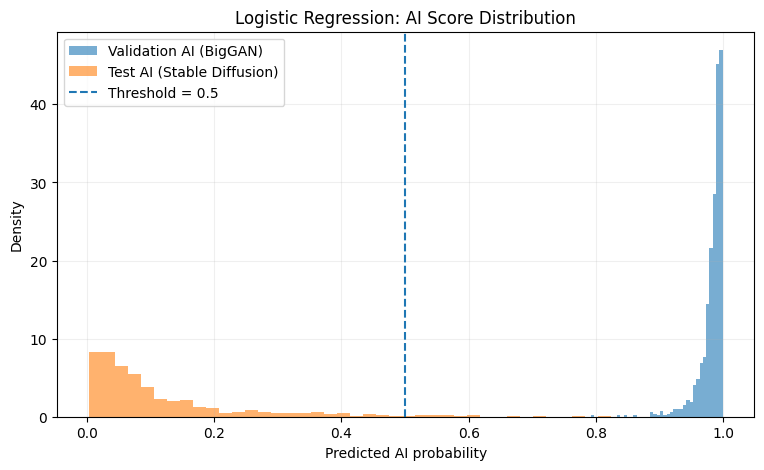

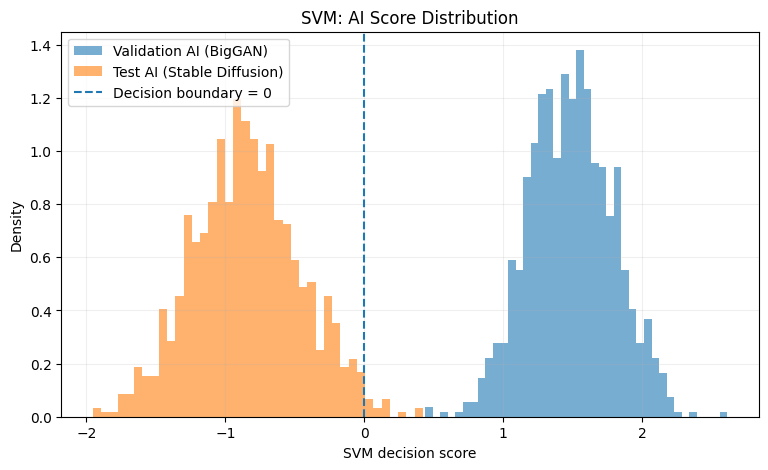

In [35]:
import matplotlib.pyplot as plt

# Logistic Regression probabilities
lr_val_scores = lr_model.predict_proba(X_val)[:, 1]
lr_test_scores = lr_model.predict_proba(X_test)[:, 1]

plt.figure(figsize=(9, 5))

plt.hist(lr_val_scores[y_val == 1], bins=40, alpha=0.6,
         label="Validation AI (BigGAN)", density=True)
plt.hist(lr_test_scores[y_test == 1], bins=40, alpha=0.6,
         label="Test AI (Stable Diffusion)", density=True)

plt.axvline(0.5, linestyle="--", label="Threshold = 0.5")
plt.xlabel("Predicted AI probability")
plt.ylabel("Density")
plt.title("Logistic Regression: AI Score Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# SVM decision scores
svm_val_scores = svm_model.decision_function(X_val)
svm_test_scores = svm_model.decision_function(X_test)

plt.figure(figsize=(9, 5))

plt.hist(svm_val_scores[y_val == 1], bins=40, alpha=0.6,
         label="Validation AI (BigGAN)", density=True)
plt.hist(svm_test_scores[y_test == 1], bins=40, alpha=0.6,
         label="Test AI (Stable Diffusion)", density=True)

plt.axvline(0, linestyle="--", label="Decision boundary = 0")
plt.xlabel("SVM decision score")
plt.ylabel("Density")
plt.title("SVM: AI Score Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [40]:
import pandas as pd
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite"

files = [
    "image_twins/verite_true_image_twin_manifest.csv",
    "image_twins/verite_accepted_vae_twin_manifest.csv",
    "image_twins/verite_corrected_vae_twin_similarity_report.csv",
]

for filename in files:
    path = os.path.join(base, filename)

    print("\n" + "="*80)
    print(filename)
    print("="*80)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))
    else:
        print("FILE NOT FOUND")


image_twins/verite_true_image_twin_manifest.csv
Shape: (338, 8)
Columns: ['caption', 'image_path', 'label', 'resolved_image_path', 'image_exists', 'image_id', 'split', 'file_exists']


,caption,image_path,label,resolved_image_path,image_exists,image_id,split,file_exists
0,Photograph shows a family that was taken away ...,images/true_0.jpg,True,/content/drive/MyDrive/twincheck/data/raw/veri...,True,true_0.jpg,train,True
1,Image shows electric scooters abandoned due to...,images/true_1.jpg,True,/content/drive/MyDrive/twincheck/data/raw/veri...,True,true_1.jpg,validation,True
2,Image shows unnamed runway model showcasing de...,images/true_2.jpg,True,/content/drive/MyDrive/twincheck/data/raw/veri...,True,true_2.jpg,train,True
3,A sketchfab 3D rendering of the actor Andre th...,images/true_3.jpg,True,/content/drive/MyDrive/twincheck/data/raw/veri...,True,true_3.jpg,train,True
4,Image shows abandoned white cars in China that...,images/true_4.jpg,True,/content/drive/MyDrive/twincheck/data/raw/veri...,True,true_4.jpg,train,True



image_twins/verite_accepted_vae_twin_manifest.csv
Shape: (323, 6)
Columns: ['image_id', 'twin_path', 'split', 'status', 'siglip2_similarity', 'accepted']


,image_id,twin_path,split,status,siglip2_similarity,accepted
0,true_0.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.934134,True
1,true_2.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.990767,True
2,true_3.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.987204,True
3,true_4.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.973360,True
4,true_5.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.979690,True



image_twins/verite_corrected_vae_twin_similarity_report.csv
Shape: (338, 6)
Columns: ['image_id', 'twin_path', 'split', 'status', 'siglip2_similarity', 'accepted']


,image_id,twin_path,split,status,siglip2_similarity,accepted
0,true_0.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.934134,True
1,true_1.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,validation,success,0.849172,False
2,true_2.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.990767,True
3,true_3.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.987204,True
4,true_4.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.973360,True


In [41]:
import pandas as pd
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins"

accepted_path = os.path.join(
    base, "verite_accepted_vae_twin_manifest.csv"
)

original_path = os.path.join(
    base, "verite_true_image_twin_manifest.csv"
)

accepted = pd.read_csv(accepted_path)
originals = pd.read_csv(original_path)

print("Accepted twin counts by split:")
print(accepted.groupby("split").size())

print("\nAccepted status:")
print(accepted["accepted"].value_counts())

print("\nOriginal image counts by split:")
print(originals.groupby("split").size())

print("\nOriginals without an accepted twin:")
accepted_ids = set(accepted.loc[accepted["accepted"] == True, "image_id"])
original_ids = set(originals["image_id"])

missing_ids = original_ids - accepted_ids
print("Count:", len(missing_ids))
print(sorted(missing_ids)[:20])

Accepted twin counts by split:
split
test           51
train         223
validation     49
dtype: int64

Accepted status:
accepted
True    323
Name: count, dtype: int64

Original image counts by split:
split
test           51
train         237
validation     50
dtype: int64

Originals without an accepted twin:
Count: 15
['true_1.jpg', 'true_139.jpg', 'true_158.jpg', 'true_164.jpg', 'true_202.jpg', 'true_205.jpg', 'true_206.jpg', 'true_217.jpg', 'true_251.jpg', 'true_284.jpg', 'true_328.jpg', 'true_333.jpg', 'true_39.jpg', 'true_46.jpg', 'true_84.jpg']


In [43]:
import os
import numpy as np
import pandas as pd

base = "/content/drive/MyDrive/twincheck/features/vision/verite"

# Original CLIP embeddings
orig_emb_path = os.path.join(
    base,
    "clip_vit_l14/verified_image_extraction/"
    "verite_clip_vit_l14_image_projected_embeddings.npy"
)

orig_manifest_path = os.path.join(
    base,
    "clip_vit_l14/verified_image_extraction/"
    "verite_clip_vit_l14_image_projected_embeddings_manifest.csv"
)

# Twin artifacts
twin_dir = os.path.join(base, "image_twins")

print("=== ORIGINAL CLIP ===")
orig_emb = np.load(orig_emb_path, mmap_mode="r")
orig_manifest = pd.read_csv(orig_manifest_path)

print("Embedding shape:", orig_emb.shape)
print("Manifest shape:", orig_manifest.shape)
print("Manifest columns:", orig_manifest.columns.tolist())
display(orig_manifest.head(3))

print("\n=== TWIN FILES ===")
for filename in sorted(os.listdir(twin_dir)):
    if "embedding" in filename.lower() or "manifest" in filename.lower():
        print(filename)

print("\n=== CORRECTED TWIN SIGLIP2 EMBEDDINGS ===")
twin_emb_path = os.path.join(
    twin_dir, "verite_corrected_vae_twin_siglip2_embeddings.npy"
)

twin_emb = np.load(twin_emb_path, mmap_mode="r")
print("Twin embedding shape:", twin_emb.shape)

=== ORIGINAL CLIP ===
Embedding shape: (663, 768)
Manifest shape: (663, 3)
Manifest columns: ['image_id', 'resolved_image_path', 'split']


,image_id,resolved_image_path,split
0,false_0.jpg,/content/drive/MyDrive/twincheck/data/raw/veri...,test
1,false_1.jpg,/content/drive/MyDrive/twincheck/data/raw/veri...,train
2,false_10.jpg,/content/drive/MyDrive/twincheck/data/raw/veri...,train



=== TWIN FILES ===
verite_accepted_vae_twin_manifest.csv
verite_corrected_vae_twin_siglip2_embeddings.npy
verite_face_filtered_vae_twin_manifest.csv
verite_true_image_twin_manifest.csv
verite_vae_twin_siglip2_embeddings.npy

=== CORRECTED TWIN SIGLIP2 EMBEDDINGS ===
Twin embedding shape: (338, 1152)


In [44]:
import pandas as pd
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite"

orig_manifest_path = os.path.join(
    base,
    "clip_vit_l14/verified_image_extraction/"
    "verite_clip_vit_l14_image_projected_embeddings_manifest.csv"
)

twin_dir = os.path.join(base, "image_twins")

orig = pd.read_csv(orig_manifest_path)

accepted = pd.read_csv(
    os.path.join(twin_dir, "verite_accepted_vae_twin_manifest.csv")
)

corrected = pd.read_csv(
    os.path.join(twin_dir, "verite_corrected_vae_twin_similarity_report.csv")
)

print("=== ORIGINAL CLIP MANIFEST ===")
print("Counts by image ID prefix:")
print(orig["image_id"].str.split("_").str[0].value_counts())

print("\nTrue images in original CLIP manifest:")
true_orig = orig[orig["image_id"].str.startswith("true_")]
print("Count:", len(true_orig))
print(true_orig["image_id"].head(10).tolist())

print("\n=== ACCEPTED TWINS ===")
print("First 10 IDs:")
print(accepted["image_id"].head(10).tolist())

print("\n=== CORRECTED TWIN REPORT ===")
print("First 10 IDs:")
print(corrected["image_id"].head(10).tolist())

print("\nTwin embedding row count:", 338)
print("Corrected report row count:", len(corrected))

=== ORIGINAL CLIP MANIFEST ===
Counts by image ID prefix:
image_id
true     338
false    325
Name: count, dtype: int64

True images in original CLIP manifest:
Count: 338
['true_0.jpg', 'true_1.jpg', 'true_10.jpg', 'true_100.jpg', 'true_101.jpg', 'true_102.jpg', 'true_103.jpg', 'true_104.jpg', 'true_105.jpg', 'true_106.jpg']

=== ACCEPTED TWINS ===
First 10 IDs:
['true_0.jpg', 'true_2.jpg', 'true_3.jpg', 'true_4.jpg', 'true_5.jpg', 'true_6.jpg', 'true_7.jpg', 'true_8.jpg', 'true_9.jpg', 'true_10.jpg']

=== CORRECTED TWIN REPORT ===
First 10 IDs:
['true_0.jpg', 'true_1.jpg', 'true_2.jpg', 'true_3.jpg', 'true_4.jpg', 'true_5.jpg', 'true_6.jpg', 'true_7.jpg', 'true_8.jpg', 'true_9.jpg']

Twin embedding row count: 338
Corrected report row count: 338


In [45]:
import numpy as np
import pandas as pd
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite"
twin_dir = os.path.join(base, "image_twins")

orig_manifest = pd.read_csv(
    os.path.join(
        base,
        "clip_vit_l14/verified_image_extraction/"
        "verite_clip_vit_l14_image_projected_embeddings_manifest.csv"
    )
)

corrected_report = pd.read_csv(
    os.path.join(twin_dir, "verite_corrected_vae_twin_similarity_report.csv")
)

accepted_manifest = pd.read_csv(
    os.path.join(twin_dir, "verite_accepted_vae_twin_manifest.csv")
)

# Keep only original true images
original_true = orig_manifest[
    orig_manifest["image_id"].str.startswith("true_")
].copy()

# Verify row ordering
print("Original true images:", len(original_true))
print("Corrected twin report:", len(corrected_report))

print(
    "\nExact ordering match:",
    original_true["image_id"].reset_index(drop=True).equals(
        corrected_report["image_id"].reset_index(drop=True)
    )
)

# Verify ID coverage
print(
    "Same IDs:",
    set(original_true["image_id"]) == set(corrected_report["image_id"])
)

# Check accepted twins
accepted_ids = set(
    accepted_manifest.loc[accepted_manifest["accepted"], "image_id"]
)

print("Accepted twin count:", len(accepted_ids))
print("Accepted IDs contained in originals:",
      accepted_ids.issubset(set(original_true["image_id"])))

# Check split consistency
split_check = original_true[["image_id", "split"]].merge(
    corrected_report[["image_id", "split"]],
    on="image_id",
    suffixes=("_original", "_twin")
)

print("\nSplit mismatches:")
print(
    split_check[
        split_check["split_original"] != split_check["split_twin"]
    ].head()
)
print(
    "Mismatch count:",
    (split_check["split_original"] != split_check["split_twin"]).sum()
)

Original true images: 338
Corrected twin report: 338

Exact ordering match: False
Same IDs: True
Accepted twin count: 323
Accepted IDs contained in originals: True

Split mismatches:
Empty DataFrame
Columns: [image_id, split_original, split_twin]
Index: []
Mismatch count: 0


In [46]:
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14"

for root, dirs, files in os.walk(base):
    for filename in files:
        print(os.path.join(root, filename))

/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/clip_extraction_config.json
/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/verite_clip_vit_l14_image_projected_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/verite_clip_vit_l14_image_projected_embeddings_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/image_embedding_batches/clip_batch_000.npz
/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/image_embedding_batches/clip_batch_001.npz
/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/image_embedding_batches/clip_batch_002.npz
/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/image_embedding_batches/clip_batch_003.npz
/content/drive/MyDrive/t

In [47]:
import json

config_path = (
    "/content/drive/MyDrive/twincheck/features/vision/verite/"
    "clip_vit_l14/verified_image_extraction/clip_extraction_config.json"
)

with open(config_path, "r") as f:
    config = json.load(f)

print(json.dumps(config, indent=2))

{
  "model_id": "openai/clip-vit-large-patch14",
  "embedding_type": "projected_image_embeddings",
  "embedding_dimension": 768,
  "normalization": "L2",
  "batch_size": 32,
  "total_images": 663,
  "expected_batches": 21,
  "manifest_sha256": "ce8925eb37f0afa0d68403f4a87f876fd08a9152b37dc975224f72de9d1b02d2",
  "device": "cuda:0"
}


In [48]:
import pandas as pd
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins"

accepted = pd.read_csv(
    os.path.join(base, "verite_accepted_vae_twin_manifest.csv")
)

accepted = accepted[accepted["accepted"] == True].copy()

accepted["path_exists"] = accepted["twin_path"].apply(os.path.exists)

print("Accepted twins:", len(accepted))
print("Existing files:", accepted["path_exists"].sum())
print("Missing files:", (~accepted["path_exists"]).sum())

print("\nCounts by split:")
print(accepted.groupby("split")["path_exists"].agg(["count", "sum"]))

if (~accepted["path_exists"]).any():
    display(accepted[~accepted["path_exists"]].head(10))

Accepted twins: 323
Existing files: 323
Missing files: 0

Counts by split:
            count  sum
split                 
test           51   51
train         223  223
validation     49   49


In [50]:
import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm
from transformers import CLIPModel, CLIPProcessor

# --------------------------------------------------
# Paths
# --------------------------------------------------
base = "/content/drive/MyDrive/twincheck/features/vision/verite"
twin_dir = os.path.join(base, "image_twins")

manifest_path = os.path.join(
    twin_dir, "verite_accepted_vae_twin_manifest.csv"
)

output_dir = os.path.join(
    twin_dir, "clip_vit_l14_twin_extraction"
)
os.makedirs(output_dir, exist_ok=True)

output_embeddings = os.path.join(
    output_dir, "verite_accepted_twin_clip_vit_l14_embeddings.npy"
)

output_manifest = os.path.join(
    output_dir, "verite_accepted_twin_clip_vit_l14_manifest.csv"
)

# --------------------------------------------------
# Load accepted twin manifest
# --------------------------------------------------
df = pd.read_csv(manifest_path)
df = df[df["accepted"] == True].copy()
df = df.reset_index(drop=True)

assert len(df) == 323
assert df["twin_path"].apply(os.path.exists).all()

# --------------------------------------------------
# Load model
# --------------------------------------------------
model_id = "openai/clip-vit-large-patch14"
device = "cuda" if torch.cuda.is_available() else "cpu"

processor = CLIPProcessor.from_pretrained(model_id)
model = CLIPModel.from_pretrained(model_id).to(device)
model.eval()

print("Device:", device)

# --------------------------------------------------
# Extract projected CLIP image embeddings
# --------------------------------------------------
batch_size = 32
all_embeddings = []
successful_rows = []

with torch.no_grad():

    for start in tqdm(range(0, len(df), batch_size)):

        batch_df = df.iloc[start:start + batch_size]

        images = []
        batch_rows = []

        for _, row in batch_df.iterrows():
            try:
                image = Image.open(row["twin_path"]).convert("RGB")
                images.append(image)
                batch_rows.append(row)
            except Exception as e:
                print("Failed:", row["image_id"], e)

        if not images:
            continue

        inputs = processor(
            images=images,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].to(device)

        # Vision encoder
        vision_outputs = model.vision_model(
            pixel_values=pixel_values
        )

        # Pooled vision features
        pooled_output = vision_outputs.pooler_output

        # CLIP projection to 768 dimensions
        features = model.visual_projection(pooled_output)

        # L2 normalization
        features = torch.nn.functional.normalize(
            features, p=2, dim=1
        )

        all_embeddings.append(features.cpu().numpy())
        successful_rows.extend(batch_rows)

# --------------------------------------------------
# Save results
# --------------------------------------------------
embeddings = np.concatenate(all_embeddings, axis=0)

successful_manifest = pd.DataFrame(successful_rows)
successful_manifest = successful_manifest.reset_index(drop=True)

assert len(embeddings) == len(successful_manifest)
assert embeddings.shape[1] == 768

np.save(output_embeddings, embeddings)
successful_manifest.to_csv(output_manifest, index=False)

print("\nExtraction completed.")
print("Embedding shape:", embeddings.shape)
print("Manifest rows:", len(successful_manifest))
print("Output embeddings:", output_embeddings)
print("Output manifest:", output_manifest)

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Device: cuda


  0%|          | 0/11 [00:00<?, ?it/s]


Extraction completed.
Embedding shape: (323, 768)
Manifest rows: 323
Output embeddings: /content/drive/MyDrive/twincheck/features/vision/verite/image_twins/clip_vit_l14_twin_extraction/verite_accepted_twin_clip_vit_l14_embeddings.npy
Output manifest: /content/drive/MyDrive/twincheck/features/vision/verite/image_twins/clip_vit_l14_twin_extraction/verite_accepted_twin_clip_vit_l14_manifest.csv


In [51]:
import os
import numpy as np
import pandas as pd

base = "/content/drive/MyDrive/twincheck/features/vision/verite"

# Original CLIP embeddings
orig_emb_path = os.path.join(
    base,
    "clip_vit_l14/verified_image_extraction/"
    "verite_clip_vit_l14_image_projected_embeddings.npy"
)

orig_manifest_path = os.path.join(
    base,
    "clip_vit_l14/verified_image_extraction/"
    "verite_clip_vit_l14_image_projected_embeddings_manifest.csv"
)

# Twin CLIP embeddings
twin_dir = os.path.join(
    base, "image_twins/clip_vit_l14_twin_extraction"
)

twin_emb_path = os.path.join(
    twin_dir, "verite_accepted_twin_clip_vit_l14_embeddings.npy"
)

twin_manifest_path = os.path.join(
    twin_dir, "verite_accepted_twin_clip_vit_l14_manifest.csv"
)

# Load
orig_embeddings = np.load(orig_emb_path)
orig_manifest = pd.read_csv(orig_manifest_path)

twin_embeddings = np.load(twin_emb_path)
twin_manifest = pd.read_csv(twin_manifest_path)

# Add embedding row indices
orig_manifest = orig_manifest.reset_index(drop=True)
twin_manifest = twin_manifest.reset_index(drop=True)

orig_manifest["orig_embedding_index"] = np.arange(len(orig_manifest))
twin_manifest["twin_embedding_index"] = np.arange(len(twin_manifest))

# Keep only original true images
orig_true = orig_manifest[
    orig_manifest["image_id"].str.startswith("true_")
].copy()

# Match originals and twins by image_id
paired = orig_true.merge(
    twin_manifest[
        ["image_id", "split", "twin_embedding_index", "twin_path"]
    ],
    on="image_id",
    suffixes=("_original", "_twin"),
    how="inner"
)

# Verify split consistency
split_mismatch = (
    paired["split_original"] != paired["split_twin"]
)

print("Matched pairs:", len(paired))
print("Split mismatches:", split_mismatch.sum())

# Extract aligned embedding matrices
X_original = orig_embeddings[
    paired["orig_embedding_index"].to_numpy()
]

X_twin = twin_embeddings[
    paired["twin_embedding_index"].to_numpy()
]

print("Original paired embeddings:", X_original.shape)
print("Twin paired embeddings:", X_twin.shape)

# Verify embedding dimensions
assert X_original.shape == X_twin.shape
assert X_original.shape[1] == 768
assert split_mismatch.sum() == 0

print("\nPair alignment verified successfully.")

# Save paired manifest
paired_path = os.path.join(
    twin_dir, "verite_original_twin_aligned_pairs.csv"
)

paired.to_csv(paired_path, index=False)

print("Saved paired manifest:", paired_path)

Matched pairs: 323
Split mismatches: 0
Original paired embeddings: (323, 768)
Twin paired embeddings: (323, 768)

Pair alignment verified successfully.
Saved paired manifest: /content/drive/MyDrive/twincheck/features/vision/verite/image_twins/clip_vit_l14_twin_extraction/verite_original_twin_aligned_pairs.csv


In [52]:
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite"

for root, dirs, files in os.walk(base):
    for filename in files:
        if any(word in filename.lower() for word in [
            "caption", "text_embedding", "similarity", "siglip"
        ]):
            print(os.path.join(root, filename))

/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verite_siglip2_image_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/siglip2_clip_manifest_comparison_report.json
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_verified_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_caption_extraction/verite_siglip2_caption_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_caption_extraction/caption_extraction_config.json
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_caption_extraction/verite_siglip2_caption_p

In [53]:
import numpy as np
import pandas as pd
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_caption_extraction"

files = {
    "original_caption_embeddings": os.path.join(
        base, "verite_siglip2_caption_projected_embeddings.npy"
    ),
    "original_caption_manifest": os.path.join(
        base, "verite_siglip2_caption_projected_embeddings_manifest.csv"
    ),
    "original_image_embeddings": "/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings.npy",
    "original_image_manifest": "/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings_manifest.csv",
    "twin_image_embeddings": "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_corrected_vae_twin_siglip2_embeddings.npy",
    "twin_similarity_report": "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_corrected_vae_twin_similarity_report.csv"
}

for name, path in files.items():
    print(f"\n--- {name} ---")
    print("Exists:", os.path.exists(path))

    if not os.path.exists(path):
        continue

    if path.endswith(".npy"):
        arr = np.load(path)
        print("Shape:", arr.shape)
        print("Dtype:", arr.dtype)

    elif path.endswith(".csv"):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))


--- original_caption_embeddings ---
Exists: True
Shape: (1001, 1152)
Dtype: float32

--- original_caption_manifest ---
Exists: True
Shape: (1001, 8)
Columns: ['caption_id', 'caption', 'image_path', 'label', 'resolved_image_path', 'image_exists', 'image_id', 'split']
         caption_id                                                                                                                                                                                                                     caption         image_path          label                                                                           resolved_image_path  image_exists    image_id split
verite_caption_0000 Photograph shows a family that was taken away by local epidemic prevention personnel after they had returned home from Hubei Province in February 2020 while they were asked to self-quarantine in their homes for 14 days.  images/true_0.jpg           true  /content/drive/MyDrive/twincheck/data/raw/verite/images_d

In [54]:
import os
import pandas as pd

twin_dir = "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins"

print("Files in twin directory:\n")
for root, dirs, files in os.walk(twin_dir):
    for f in files:
        print(os.path.join(root, f))

Files in twin directory:

/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_true_image_twin_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_vae_twin_checkpoint.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_vae_twin_report.json
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_vae_twin_siglip2_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_vae_twin_similarity_report.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_corrected_vae_pilot_report.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_corrected_vae_generation_checkpoint.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_corrected_vae_twin_similarity_report.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_corrected_vae_twin_siglip2_embeddings.npy
/content

In [55]:
import pandas as pd
import numpy as np
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite"

paths = {
    "accepted_twin_manifest": f"{base}/image_twins/verite_accepted_vae_twin_manifest.csv",
    "corrected_twin_report": f"{base}/image_twins/verite_corrected_vae_twin_similarity_report.csv",
    "caption_manifest": f"{base}/siglip2/verified_caption_extraction/verite_siglip2_caption_projected_embeddings_manifest.csv",
    "image_manifest": f"{base}/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings_manifest.csv",
}

for name, path in paths.items():
    print(f"\n{'='*60}")
    print(name)
    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(5).to_string(index=False))


accepted_twin_manifest
Shape: (323, 6)
Columns: ['image_id', 'twin_path', 'split', 'status', 'siglip2_similarity', 'accepted']
  image_id                                                                                                   twin_path split  status  siglip2_similarity  accepted
true_0.jpg /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_0_V_corrected.jpg train success            0.934134      True
true_2.jpg /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_2_V_corrected.jpg train success            0.990767      True
true_3.jpg /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_3_V_corrected.jpg train success            0.987204      True
true_4.jpg /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_4_V_corrected.jpg train success            0.973360      True
true_5.jpg                 /content/drive/MyDrive/twinche

In [56]:
import numpy as np
import pandas as pd

base = "/content/drive/MyDrive/twincheck/features/vision/verite"

# Load files
img_emb = np.load(
    f"{base}/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings.npy"
)
cap_emb = np.load(
    f"{base}/siglip2/verified_caption_extraction/verite_siglip2_caption_projected_embeddings.npy"
)
twin_emb = np.load(
    f"{base}/image_twins/verite_corrected_vae_twin_siglip2_embeddings.npy"
)

img_manifest = pd.read_csv(
    f"{base}/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings_manifest.csv"
)
cap_manifest = pd.read_csv(
    f"{base}/siglip2/verified_caption_extraction/verite_siglip2_caption_projected_embeddings_manifest.csv"
)
twin_report = pd.read_csv(
    f"{base}/image_twins/verite_corrected_vae_twin_similarity_report.csv"
)
accepted = pd.read_csv(
    f"{base}/image_twins/verite_accepted_vae_twin_manifest.csv"
)

print("Embedding shapes:")
print("Images:", img_emb.shape)
print("Captions:", cap_emb.shape)
print("Twins:", twin_emb.shape)

print("\nRow count check:")
print("Image embeddings == manifest:", len(img_emb) == len(img_manifest))
print("Caption embeddings == manifest:", len(cap_emb) == len(cap_manifest))
print("Twin embeddings == report:", len(twin_emb) == len(twin_report))

print("\nTwin ordering preview:")
print(twin_report[["image_id", "accepted", "twin_path"]].head(10).to_string(index=False))

print("\nEmbedding norms:")
print("Image norms:", np.linalg.norm(img_emb[:5], axis=1))
print("Caption norms:", np.linalg.norm(cap_emb[:5], axis=1))
print("Twin norms:", np.linalg.norm(twin_emb[:5], axis=1))

print("\nAccepted twin count:", len(accepted))
print("Accepted IDs unique:", accepted["image_id"].is_unique)
print("Report IDs unique:", twin_report["image_id"].is_unique)

Embedding shapes:
Images: (663, 1152)
Captions: (1001, 1152)
Twins: (338, 1152)

Row count check:
Image embeddings == manifest: True
Caption embeddings == manifest: True
Twin embeddings == report: True

Twin ordering preview:
  image_id  accepted                                                                                                   twin_path
true_0.jpg      True /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_0_V_corrected.jpg
true_1.jpg     False /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_1_V_corrected.jpg
true_2.jpg      True /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_2_V_corrected.jpg
true_3.jpg      True /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_3_V_corrected.jpg
true_4.jpg      True /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_4_V_corrected.jpg


In [57]:
import numpy as np
import pandas as pd
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite"

# Load embeddings and manifests
img_emb = np.load(
    f"{base}/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings.npy"
)
cap_emb = np.load(
    f"{base}/siglip2/verified_caption_extraction/verite_siglip2_caption_projected_embeddings.npy"
)
twin_emb = np.load(
    f"{base}/image_twins/verite_corrected_vae_twin_siglip2_embeddings.npy"
)

img_manifest = pd.read_csv(
    f"{base}/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings_manifest.csv"
)
cap_manifest = pd.read_csv(
    f"{base}/siglip2/verified_caption_extraction/verite_siglip2_caption_projected_embeddings_manifest.csv"
)
twin_report = pd.read_csv(
    f"{base}/image_twins/verite_corrected_vae_twin_similarity_report.csv"
)

# Add embedding row indices
img_manifest = img_manifest.copy()
img_manifest["embedding_index"] = np.arange(len(img_manifest))

cap_manifest = cap_manifest.copy()
cap_manifest["embedding_index"] = np.arange(len(cap_manifest))

twin_report = twin_report.copy()
twin_report["embedding_index"] = np.arange(len(twin_report))

# Keep accepted twins only
accepted = twin_report[twin_report["accepted"] == True].copy()

# Create lookup tables
image_lookup = img_manifest.set_index("image_id")
twin_lookup = accepted.set_index("image_id")

# Find captions for each image and pair with accepted twins
rows = []

for _, cap_row in cap_manifest.iterrows():

    image_id = cap_row["image_id"]

    # Only images with accepted twins
    if image_id not in image_lookup.index or image_id not in twin_lookup.index:
        continue

    image_idx = image_lookup.loc[image_id, "embedding_index"]
    twin_idx = twin_lookup.loc[image_id, "embedding_index"]
    caption_idx = cap_row["embedding_index"]

    # Cosine similarity (embeddings already normalized)
    original_score = float(np.dot(img_emb[image_idx], cap_emb[caption_idx]))
    twin_score = float(np.dot(twin_emb[twin_idx], cap_emb[caption_idx]))

    rows.append({
        "image_id": image_id,
        "caption_id": cap_row["caption_id"],
        "caption": cap_row["caption"],
        "caption_label": cap_row["label"],
        "split": cap_row["split"],
        "original_similarity": original_score,
        "twin_similarity": twin_score,
        "similarity_difference": twin_score - original_score
    })

scores = pd.DataFrame(rows)

print("Paired caption-image scores:", scores.shape)
print("Unique paired images:", scores["image_id"].nunique())
print("Unique captions:", scores["caption_id"].nunique())

print("\nScore summary:")
print(scores[[
    "original_similarity",
    "twin_similarity",
    "similarity_difference"
]].describe())

print("\nBy caption label:")
print(
    scores.groupby("caption_label")[
        ["original_similarity", "twin_similarity", "similarity_difference"]
    ].mean()
)

# Save results
output_path = f"{base}/image_twins/accepted_twin_original_caption_similarity_scores.csv"

scores.to_csv(output_path, index=False)

print("\nSaved:")
print(output_path)

Paired caption-image scores: (646, 8)
Unique paired images: 323
Unique captions: 646

Score summary:
       original_similarity  twin_similarity  similarity_difference
count           646.000000       646.000000             646.000000
mean              0.158119         0.158881               0.000762
std               0.044041         0.044622               0.008695
min               0.029305         0.029968              -0.026810
25%               0.129061         0.128516              -0.004024
50%               0.158640         0.159881               0.000585
75%               0.185303         0.186803               0.005488
max               0.293988         0.295673               0.036740

By caption label:
               original_similarity  twin_similarity  similarity_difference
caption_label                                                             
miscaptioned              0.156194         0.157094               0.000901
true                      0.160045         0.160668 

In [58]:
import os

base = "/content/drive/MyDrive/twincheck"

keywords = [
    "verite",
    "leakage",
    "verdict",
    "prediction",
    "classifier",
    "fused",
    "decoupled",
    "alr"
]

for root, dirs, files in os.walk(base):
    # Avoid unnecessarily scanning large raw data folders
    dirs[:] = [d for d in dirs if d not in ["raw", "images_download", "cache"]]

    for f in files:
        if any(k in f.lower() for k in keywords):
            print(os.path.join(root, f))

/content/drive/MyDrive/twincheck/data/processed/vision/verite_cleaned.csv
/content/drive/MyDrive/twincheck/data/processed/vision/verite_validation_report.json
/content/drive/MyDrive/twincheck/data/processed/vision/verite.jsonl
/content/drive/MyDrive/twincheck/data/processed/vision/genimage_leakage_check_report.json
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_twins_pilot/VERITE_true_1_V2.jpg
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_twins_pilot/VERITE_true_6_V2.jpg
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_twins_pilot/VERITE_true_11_V2.jpg
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_twins_pilot/VERITE_true_22_V2.jpg
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_twins_pilot/VERITE_true_27_V2.jpg
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_originals_jpeg/VERITE_true_1.jpg
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_originals_jpeg/VERITE_true_6.jpg
/content/drive/MyDrive/twincheck/data/copies/visio

In [59]:
import pandas as pd
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite"

# Load original VERITE records
records_path = "/content/drive/MyDrive/twincheck/data/processed/vision/verite.jsonl"

import json
with open(records_path, "r", encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

verite_df = pd.DataFrame(records)

# Load accepted twin manifest
twin_dir = os.path.join(base, "image_twins")
accepted = pd.read_csv(
    os.path.join(twin_dir, "verite_accepted_vae_twin_manifest.csv")
)

accepted_ids = set(
    accepted.loc[accepted["accepted"] == True, "image_id"]
)

# Get records corresponding to accepted twins
paired_records = verite_df[
    verite_df["image_path"].apply(lambda x: os.path.basename(x) in accepted_ids)
].copy()

print("=" * 60)
print("ACCEPTED TWIN DATASET AUDIT")
print("=" * 60)

print("\nAccepted unique images:", len(accepted_ids))
print("Records associated with accepted images:", len(paired_records))

print("\nCaption label distribution:")
print(paired_records["label"].value_counts())

print("\nLabels per image:")
print(
    paired_records.groupby(
        paired_records["image_path"].apply(os.path.basename)
    )["label"].nunique().value_counts()
)

print("\nExample paired records:")
display(
    paired_records[
        ["image_path", "label", "caption"]
    ].head(10)
)

ACCEPTED TWIN DATASET AUDIT

Accepted unique images: 323
Records associated with accepted images: 646

Caption label distribution:
label
true            323
miscaptioned    323
Name: count, dtype: int64

Labels per image:
label
2    323
Name: count, dtype: int64

Example paired records:


,image_path,label,caption
0,images/true_0.jpg,true,Photograph shows a family that was taken away ...
1,images/true_0.jpg,miscaptioned,Photograph shows Chinese officials in white pr...
6,images/true_2.jpg,true,Image shows unnamed runway model showcasing de...
7,images/true_2.jpg,miscaptioned,Image shows Balenciaga stylist Lotta Volkova h...
9,images/true_3.jpg,true,A sketchfab 3D rendering of the actor Andre th...
10,images/true_3.jpg,miscaptioned,"3D model accurately depicting what Joseph, hus..."
12,images/true_4.jpg,true,Image shows abandoned white cars in China that...
13,images/true_4.jpg,miscaptioned,Image shows hundreds of white electric cars th...
15,images/true_5.jpg,true,Image shows athletes resting in hammocks while...
16,images/true_5.jpg,miscaptioned,Image shows campers sleeping in hammocks suspe...


In [61]:
print("Label distribution:")
print(scores["caption_label"].value_counts())

print("\nMissing values:")
print(scores.isna().sum())

print("\nSplit distribution:")
print(scores["split"].value_counts())

print("\nUnique images per split:")
print(scores.groupby("split")["image_id"].nunique())

print("\nSimilarity statistics by caption label:")
display(
    scores.groupby("caption_label")[
        ["original_similarity", "twin_similarity", "similarity_difference"]
    ].mean()
)

Label distribution:
caption_label
true            323
miscaptioned    323
Name: count, dtype: int64

Missing values:
image_id                 0
caption_id               0
caption                  0
caption_label            0
split                    0
original_similarity      0
twin_similarity          0
similarity_difference    0
dtype: int64

Split distribution:
split
train         446
test          102
validation     98
Name: count, dtype: int64

Unique images per split:
split
test           51
train         223
validation     49
Name: image_id, dtype: int64

Similarity statistics by caption label:


,original_similarity,twin_similarity,similarity_difference
caption_label,,,
miscaptioned,0.156194,0.157094,0.000901
true,0.160045,0.160668,0.000623


In [62]:
import pandas as pd
import numpy as np

# One row per image, comparing the two captions
results = []

for image_id, group in scores.groupby("image_id"):

    true_row = group[group["caption_label"] == "true"].iloc[0]
    false_row = group[group["caption_label"] == "miscaptioned"].iloc[0]

    # Original image: select caption with higher similarity
    original_selected = (
        "true"
        if true_row["original_similarity"] > false_row["original_similarity"]
        else "miscaptioned"
    )

    # Twin image: select caption with higher similarity
    twin_selected = (
        "true"
        if true_row["twin_similarity"] > false_row["twin_similarity"]
        else "miscaptioned"
    )

    results.append({
        "image_id": image_id,
        "split": group["split"].iloc[0],
        "original_selected": original_selected,
        "twin_selected": twin_selected,
        "verdict_changed": original_selected != twin_selected,
        "original_correct": original_selected == "true",
        "twin_correct": twin_selected == "true",
        "original_margin": (
            true_row["original_similarity"]
            - false_row["original_similarity"]
        ),
        "twin_margin": (
            true_row["twin_similarity"]
            - false_row["twin_similarity"]
        )
    })

decoupled_results = pd.DataFrame(results)

print("Total paired images:", len(decoupled_results))
print("\nOriginal accuracy:", decoupled_results["original_correct"].mean())
print("Twin accuracy:", decoupled_results["twin_correct"].mean())

alr = decoupled_results["verdict_changed"].mean() * 100
print(f"\nDecoupled ALR: {alr:.2f}%")

print("\nVerdict changes:")
print(decoupled_results["verdict_changed"].value_counts())

print("\nResults by split:")
display(
    decoupled_results.groupby("split").agg(
        images=("image_id", "count"),
        original_accuracy=("original_correct", "mean"),
        twin_accuracy=("twin_correct", "mean"),
        verdict_changes=("verdict_changed", "sum"),
        ALR_percent=("verdict_changed", lambda x: x.mean() * 100)
    )
)

print("\nExamples where verdict changed:")
display(
    decoupled_results[
        decoupled_results["verdict_changed"]
    ].head(10)
)

Total paired images: 323

Original accuracy: 0.56656346749226
Twin accuracy: 0.541795665634675

Decoupled ALR: 9.29%

Verdict changes:
verdict_changed
False    293
True      30
Name: count, dtype: int64

Results by split:


,images,original_accuracy,twin_accuracy,verdict_changes,ALR_percent
split,,,,,
test,51,0.607843,0.607843,4,7.843137
train,223,0.565022,0.538117,20,8.968610
validation,49,0.530612,0.489796,6,12.244898



Examples where verdict changed:


,image_id,split,original_selected,twin_selected,verdict_changed,original_correct,twin_correct,original_margin,twin_margin
2,true_100.jpg,train,true,miscaptioned,True,True,False,0.000929,-0.000407
12,true_11.jpg,validation,true,miscaptioned,True,True,False,0.010228,-0.000777
20,true_117.jpg,validation,miscaptioned,true,True,False,True,-0.005955,0.002893
26,true_122.jpg,validation,miscaptioned,true,True,False,True,-0.007233,0.002707
62,true_156.jpg,test,true,miscaptioned,True,True,False,0.003992,-0.002312
68,true_162.jpg,test,miscaptioned,true,True,False,True,-0.005018,0.001866
75,true_17.jpg,train,miscaptioned,true,True,False,True,-0.000393,0.003719
112,true_203.jpg,train,true,miscaptioned,True,True,False,0.000632,-0.005149
113,true_204.jpg,train,true,miscaptioned,True,True,False,0.000524,-0.003183
124,true_216.jpg,train,miscaptioned,true,True,False,True,-0.007939,0.004730


In [63]:
import os
import json

output_dir = "/content/drive/MyDrive/twincheck/results/F3"
os.makedirs(output_dir, exist_ok=True)

# Save image-level paired decisions
decoupled_results.to_csv(
    os.path.join(output_dir, "F3_decoupled_similarity_baseline_results.csv"),
    index=False
)

# Save summary
summary = {
    "method": "Decoupled similarity-ranking baseline",
    "total_paired_images": int(len(decoupled_results)),
    "original_accuracy": float(decoupled_results["original_correct"].mean()),
    "twin_accuracy": float(decoupled_results["twin_correct"].mean()),
    "verdict_changes": int(decoupled_results["verdict_changed"].sum()),
    "ALR_percent": float(decoupled_results["verdict_changed"].mean() * 100),
    "unchanged_verdicts": int((~decoupled_results["verdict_changed"]).sum()),
    "split_results": {}
}

for split, group in decoupled_results.groupby("split"):
    summary["split_results"][split] = {
        "images": int(len(group)),
        "original_accuracy": float(group["original_correct"].mean()),
        "twin_accuracy": float(group["twin_correct"].mean()),
        "verdict_changes": int(group["verdict_changed"].sum()),
        "ALR_percent": float(group["verdict_changed"].mean() * 100)
    }

summary_path = os.path.join(
    output_dir,
    "F3_decoupled_similarity_baseline_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("Saved files:")
print(os.path.join(output_dir, "F3_decoupled_similarity_baseline_results.csv"))
print(summary_path)
print("\nSummary saved successfully.")

Saved files:
/content/drive/MyDrive/twincheck/results/F3/F3_decoupled_similarity_baseline_results.csv
/content/drive/MyDrive/twincheck/results/F3/F3_decoupled_similarity_baseline_summary.json

Summary saved successfully.


In [64]:
import os

base = "/content/drive/MyDrive/twincheck"

keywords = [
    "authenticity",
    "authentic",
    "probe",
    "logistic",
    "svm",
    "prediction",
    "score",
    "clip"
]

print("Existing F3-related artifacts:\n")

for root, dirs, files in os.walk(base):
    # Avoid scanning raw datasets and image directories
    dirs[:] = [
        d for d in dirs
        if d.lower() not in ["images", "raw", "cache", "__pycache__"]
    ]

    for filename in files:
        if filename.lower().endswith((".csv", ".npy", ".json", ".pkl", ".pt")):
            if any(keyword in filename.lower() for keyword in keywords):
                print(os.path.join(root, filename))

Existing F3-related artifacts:

/content/drive/MyDrive/twincheck/data/processed/vision/f3_authenticity_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/siglip2_clip_manifest_comparison_report.json
/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/clip_extraction_config.json
/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/verite_clip_vit_l14_image_projected_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction/verite_clip_vit_l14_image_projected_embeddings_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/accepted_twin_original_caption_similarity_scores.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/clip_vit_l14_twin_extraction/verite_accepted_twin_clip_vit_l14_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/clip_vit_l14_twi

In [65]:
import pandas as pd

manifest_path = "/content/drive/MyDrive/twincheck/data/processed/vision/f3_authenticity_manifest.csv"

auth_manifest = pd.read_csv(manifest_path)

print("Shape:", auth_manifest.shape)
print("\nColumns:")
print(auth_manifest.columns.tolist())

print("\nFirst rows:")
display(auth_manifest.head())

print("\nLabel counts:")
for col in auth_manifest.columns:
    if "label" in col.lower() or "class" in col.lower():
        print(f"\n{col}:")
        print(auth_manifest[col].value_counts())

print("\nSplit counts:")
for col in auth_manifest.columns:
    if "split" in col.lower():
        print(f"\n{col}:")
        print(auth_manifest[col].value_counts())

Shape: (13000, 4)

Columns:
['image_path', 'split', 'label', 'generator']

First rows:


,image_path,split,label,generator
0,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
1,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
2,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
3,/content/drive/MyDrive/twincheck/data/processe...,train,0,real
4,/content/drive/MyDrive/twincheck/data/processe...,train,0,real



Label counts:

label:
label
1    7000
0    6000
Name: count, dtype: int64

Split counts:

split:
split
train         9000
validation    2000
test          2000
Name: count, dtype: int64


In [66]:
import os

base = "/content/drive/MyDrive/twincheck"

extensions = (".pkl", ".joblib", ".pt", ".pth", ".json", ".csv", ".npy")

keywords = [
    "model", "classifier", "authenticity",
    "prediction", "predictions", "probability",
    "probabilities", "logistic", "svm",
    "checkpoint", "metrics"
]

print("Potential saved model and prediction files:\n")

for root, dirs, files in os.walk(base):
    dirs[:] = [
        d for d in dirs
        if d.lower() not in ["images", "raw", "cache", "__pycache__"]
    ]

    for filename in files:
        if filename.lower().endswith(extensions):
            if any(k in filename.lower() for k in keywords):
                print(os.path.join(root, filename))

Potential saved model and prediction files:

/content/drive/MyDrive/twincheck/data/processed/vision/f3_authenticity_manifest.csv
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_pilot_checkpoint.csv
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_pilot_s015_checkpoint.csv
/content/drive/MyDrive/twincheck/data/copies/vision/sdxl_twins_s015_checkpoint.csv
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/checkpoints/verite_image_embeddings_checkpoint.npy
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/checkpoints/verite_image_projected_checkpoint.npy
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_vae_twin_checkpoint.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_corrected_vae_generation_checkpoint.csv
/content/drive/MyDrive/twincheck/features/vision/m4fc/image_twins/m4fc_corrected_vae_generation_checkpoint.csv
/content/drive/MyDrive/twincheck/features/vision/jpeg85_final/siglip2/jpe

In [67]:
import numpy as np
import pandas as pd
import os

verite_clip_dir = "/content/drive/MyDrive/twincheck/features/vision/verite/clip_vit_l14/verified_image_extraction"

twin_clip_dir = "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/clip_vit_l14_twin_extraction"

original_emb_path = os.path.join(
    verite_clip_dir,
    "verite_clip_vit_l14_image_projected_embeddings.npy"
)

original_manifest_path = os.path.join(
    verite_clip_dir,
    "verite_clip_vit_l14_image_projected_embeddings_manifest.csv"
)

twin_emb_path = os.path.join(
    twin_clip_dir,
    "verite_accepted_twin_clip_vit_l14_embeddings.npy"
)

twin_manifest_path = os.path.join(
    twin_clip_dir,
    "verite_accepted_twin_clip_vit_l14_manifest.csv"
)

# Load manifests
original_manifest = pd.read_csv(original_manifest_path)
twin_manifest = pd.read_csv(twin_manifest_path)

# Load embeddings
original_embeddings = np.load(original_emb_path)
twin_embeddings = np.load(twin_emb_path)

print("ORIGINAL VERITE")
print("Embedding shape:", original_embeddings.shape)
print("Manifest shape:", original_manifest.shape)
print("Manifest columns:", original_manifest.columns.tolist())

print("\nTWIN VERITE")
print("Embedding shape:", twin_embeddings.shape)
print("Manifest shape:", twin_manifest.shape)
print("Manifest columns:", twin_manifest.columns.tolist())

print("\nFirst original manifest rows:")
display(original_manifest.head())

print("\nFirst twin manifest rows:")
display(twin_manifest.head())

print("\nEmbedding dimensions match:",
      original_embeddings.shape[1] == twin_embeddings.shape[1])

print("\nRows aligned with manifests:",
      len(original_embeddings) == len(original_manifest),
      len(twin_embeddings) == len(twin_manifest))

ORIGINAL VERITE
Embedding shape: (663, 768)
Manifest shape: (663, 3)
Manifest columns: ['image_id', 'resolved_image_path', 'split']

TWIN VERITE
Embedding shape: (323, 768)
Manifest shape: (323, 6)
Manifest columns: ['image_id', 'twin_path', 'split', 'status', 'siglip2_similarity', 'accepted']

First original manifest rows:


,image_id,resolved_image_path,split
0,false_0.jpg,/content/drive/MyDrive/twincheck/data/raw/veri...,test
1,false_1.jpg,/content/drive/MyDrive/twincheck/data/raw/veri...,train
2,false_10.jpg,/content/drive/MyDrive/twincheck/data/raw/veri...,train
3,false_100.jpg,/content/drive/MyDrive/twincheck/data/raw/veri...,train
4,false_101.jpg,/content/drive/MyDrive/twincheck/data/raw/veri...,validation



First twin manifest rows:


,image_id,twin_path,split,status,siglip2_similarity,accepted
0,true_0.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.934134,True
1,true_2.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.990767,True
2,true_3.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.987204,True
3,true_4.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.973360,True
4,true_5.jpg,/content/drive/MyDrive/twincheck/data/copies/v...,train,success,0.979690,True



Embedding dimensions match: True

Rows aligned with manifests: True True


In [68]:
import numpy as np
import pandas as pd
import os

feature_dir = "/content/drive/MyDrive/twincheck/features/vision/genimage"

clip_path = os.path.join(
    feature_dir,
    "genimage_clip_vit_l14_image_projected_embeddings.npy"
)

embedding_manifest_path = os.path.join(
    feature_dir,
    "genimage_image_embedding_manifest.csv"
)

f3_manifest_path = "/content/drive/MyDrive/twincheck/data/processed/vision/f3_authenticity_manifest.csv"

genimage_embeddings = np.load(clip_path, mmap_mode="r")
genimage_embedding_manifest = pd.read_csv(embedding_manifest_path)
f3_manifest = pd.read_csv(f3_manifest_path)

print("Embedding shape:", genimage_embeddings.shape)
print("Embedding manifest shape:", genimage_embedding_manifest.shape)

print("\nEmbedding manifest columns:")
print(genimage_embedding_manifest.columns.tolist())

print("\nF3 manifest shape:", f3_manifest.shape)

# Verify path coverage
embedding_paths = set(genimage_embedding_manifest["image_path"])
f3_paths = set(f3_manifest["image_path"])

matched = embedding_paths.intersection(f3_paths)

print("\nF3 manifest images:", len(f3_paths))
print("Images with embeddings:", len(matched))
print("Missing embeddings:", len(f3_paths - embedding_paths))
print("Coverage:", round(len(matched) / len(f3_paths) * 100, 2), "%")

# Verify the row alignment
assert len(genimage_embeddings) == len(genimage_embedding_manifest)
print("\nEmbedding-manifest row alignment: PASSED")

Embedding shape: (18000, 768)
Embedding manifest shape: (18000, 5)

Embedding manifest columns:
['image_id', 'image_path', 'split', 'class_name', 'generator']

F3 manifest shape: (13000, 4)

F3 manifest images: 13000
Images with embeddings: 13000
Missing embeddings: 0
Coverage: 100.0 %

Embedding-manifest row alignment: PASSED


In [69]:
import numpy as np
import pandas as pd
import os

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score

# --------------------------------------------------
# 1. ALIGN GENIMAGE EMBEDDINGS WITH F3 MANIFEST
# --------------------------------------------------

path_to_index = {
    path: idx
    for idx, path in enumerate(genimage_embedding_manifest["image_path"])
}

indices = f3_manifest["image_path"].map(path_to_index).to_numpy()

assert not pd.isna(indices).any()

X = genimage_embeddings[indices]
y = f3_manifest["label"].to_numpy()
splits = f3_manifest["split"].to_numpy()

X_train = X[splits == "train"]
y_train = y[splits == "train"]

X_val = X[splits == "validation"]
y_val = y[splits == "validation"]

X_test = X[splits == "test"]
y_test = y[splits == "test"]

# --------------------------------------------------
# 2. TRAIN LOGISTIC REGRESSION
# Same settings as notebook
# --------------------------------------------------

lr_reconstructed = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_reconstructed.fit(X_train, y_train)

print("Training completed.")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# --------------------------------------------------
# 3. VALIDATION THRESHOLD SELECTION
# --------------------------------------------------

val_scores = lr_reconstructed.predict_proba(X_val)[:, 1]

thresholds = np.unique(val_scores)

threshold_results = []

for threshold in thresholds:
    pred = (val_scores >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "f1": f1_score(y_val, pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, pred)
    })

best_threshold = max(
    threshold_results,
    key=lambda x: x["f1"]
)["threshold"]

print("\nValidation-selected threshold:", best_threshold)
print("Validation F1:",
      f1_score(y_val, (val_scores >= best_threshold).astype(int)))

# --------------------------------------------------
# 4. TEST EVALUATION
# --------------------------------------------------

test_scores = lr_reconstructed.predict_proba(X_test)[:, 1]
test_pred = (test_scores >= best_threshold).astype(int)

print("\n=== RECONSTRUCTED LR TEST PERFORMANCE ===")
print("Accuracy:", accuracy_score(y_test, test_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_test, test_pred))
print("F1:", f1_score(y_test, test_pred))

# --------------------------------------------------
# 5. SCORE VERITE ORIGINAL AND TWIN EMBEDDINGS
# --------------------------------------------------

# Original VERITE embeddings/manifests
orig_emb = original_embeddings
orig_manifest = original_manifest.copy()

# Twin embeddings/manifests
twin_emb = twin_embeddings
twin_manifest = twin_manifest.copy()

# Add row indices
orig_manifest = orig_manifest.reset_index(drop=True)
twin_manifest = twin_manifest.reset_index(drop=True)

orig_manifest["embedding_index"] = np.arange(len(orig_manifest))
twin_manifest["embedding_index"] = np.arange(len(twin_manifest))

# Keep only images with accepted twins
accepted_pairs = orig_manifest.merge(
    twin_manifest[
        ["image_id", "split", "embedding_index", "twin_path"]
    ],
    on="image_id",
    suffixes=("_original", "_twin"),
    how="inner"
)

assert len(accepted_pairs) == 323

# Check split consistency
assert (
    accepted_pairs["split_original"]
    == accepted_pairs["split_twin"]
).all()

# Extract paired embeddings
X_verite_original = orig_emb[
    accepted_pairs["embedding_index_original"].to_numpy()
]

X_verite_twin = twin_emb[
    accepted_pairs["embedding_index_twin"].to_numpy()
]

# Score with reconstructed LR probe
original_auth_scores = lr_reconstructed.predict_proba(
    X_verite_original
)[:, 1]

twin_auth_scores = lr_reconstructed.predict_proba(
    X_verite_twin
)[:, 1]

# Apply validation-selected threshold
original_auth_pred = (
    original_auth_scores >= best_threshold
).astype(int)

twin_auth_pred = (
    twin_auth_scores >= best_threshold
).astype(int)

# --------------------------------------------------
# 6. CREATE SCORE TABLE
# --------------------------------------------------

auth_scores_df = pd.DataFrame({
    "image_id": accepted_pairs["image_id"],
    "split": accepted_pairs["split_original"],
    "original_authenticity_score": original_auth_scores,
    "twin_authenticity_score": twin_auth_scores,
    "original_authenticity_pred": original_auth_pred,
    "twin_authenticity_pred": twin_auth_pred,
    "authenticity_prediction_changed": (
        original_auth_pred != twin_auth_pred
    ),
    "authenticity_score_difference": (
        twin_auth_scores - original_auth_scores
    )
})

print("\n=== VERITE AUTHENTICITY SCORES ===")
print("Paired images:", len(auth_scores_df))

print("\nScore summary:")
display(
    auth_scores_df[
        [
            "original_authenticity_score",
            "twin_authenticity_score",
            "authenticity_score_difference"
        ]
    ].describe()
)

print("\nPrediction changes:")
print(auth_scores_df["authenticity_prediction_changed"].value_counts())

print(
    "\nAuthenticity prediction-change rate:",
    round(
        auth_scores_df["authenticity_prediction_changed"].mean() * 100,
        2
    ),
    "%"
)

print("\nResults by split:")
display(
    auth_scores_df.groupby("split").agg(
        images=("image_id", "count"),
        original_mean_score=("original_authenticity_score", "mean"),
        twin_mean_score=("twin_authenticity_score", "mean"),
        prediction_changes=("authenticity_prediction_changed", "sum"),
        change_rate=("authenticity_prediction_changed",
                     lambda x: x.mean() * 100)
    )
)

# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------

output_dir = "/content/drive/MyDrive/twincheck/results/F3"
os.makedirs(output_dir, exist_ok=True)

score_output = os.path.join(
    output_dir,
    "F3_VERITE_authenticity_probe_original_twin_scores.csv"
)

auth_scores_df.to_csv(score_output, index=False)

print("\nSaved authenticity score comparison:")
print(score_output)

Training completed.
Train: (9000, 768)
Validation: (2000, 768)
Test: (2000, 768)

Validation-selected threshold: 0.7916609419598541
Validation F1: 1.0

=== RECONSTRUCTED LR TEST PERFORMANCE ===
Accuracy: 0.5005
Balanced accuracy: 0.5005
F1: 0.001998001998001998

=== VERITE AUTHENTICITY SCORES ===
Paired images: 323

Score summary:


,original_authenticity_score,twin_authenticity_score,authenticity_score_difference
count,323.000000,323.000000,323.000000
mean,0.025436,0.031008,0.005572
std,0.032699,0.034322,0.019058
min,0.001445,0.002631,-0.189215
25%,0.009044,0.011369,-0.000062
50%,0.015798,0.020033,0.002514
75%,0.029183,0.033493,0.008658
max,0.295992,0.266236,0.090209



Prediction changes:
authenticity_prediction_changed
False    323
Name: count, dtype: int64

Authenticity prediction-change rate: 0.0 %

Results by split:


,images,original_mean_score,twin_mean_score,prediction_changes,change_rate
split,,,,,
test,51,0.019268,0.023752,0,0.0
train,223,0.026832,0.031439,0,0.0
validation,49,0.025501,0.036600,0,0.0



Saved authenticity score comparison:
/content/drive/MyDrive/twincheck/results/F3/F3_VERITE_authenticity_probe_original_twin_scores.csv


In [70]:
import pandas as pd
import os

similarity_path = (
    "/content/drive/MyDrive/twincheck/features/vision/verite/"
    "image_twins/accepted_twin_original_caption_similarity_scores.csv"
)

similarity_df = pd.read_csv(similarity_path)

print("Shape:", similarity_df.shape)
print("\nColumns:")
print(similarity_df.columns.tolist())

print("\nFirst 5 rows:")
display(similarity_df.head())

print("\nCaption labels:")
print(similarity_df["caption_label"].value_counts())

print("\nSplit counts:")
print(similarity_df["split"].value_counts())

print("\nMissing values:")
print(similarity_df.isna().sum())

print("\nUnique image IDs:", similarity_df["image_id"].nunique())
print("Unique caption IDs:", similarity_df["caption_id"].nunique())

Shape: (646, 8)

Columns:
['image_id', 'caption_id', 'caption', 'caption_label', 'split', 'original_similarity', 'twin_similarity', 'similarity_difference']

First 5 rows:


,image_id,caption_id,caption,caption_label,split,original_similarity,twin_similarity,similarity_difference
0,true_0.jpg,verite_caption_0000,Photograph shows a family that was taken away ...,true,train,0.119700,0.107470,-0.012230
1,true_0.jpg,verite_caption_0001,Photograph shows Chinese officials in white pr...,miscaptioned,train,0.139208,0.136844,-0.002364
2,true_2.jpg,verite_caption_0006,Image shows unnamed runway model showcasing de...,true,train,0.109869,0.105344,-0.004525
3,true_2.jpg,verite_caption_0007,Image shows Balenciaga stylist Lotta Volkova h...,miscaptioned,train,0.233340,0.237698,0.004357
4,true_3.jpg,verite_caption_0009,A sketchfab 3D rendering of the actor Andre th...,true,train,0.159043,0.151380,-0.007663



Caption labels:
caption_label
true            323
miscaptioned    323
Name: count, dtype: int64

Split counts:
split
train         446
test          102
validation     98
Name: count, dtype: int64

Missing values:
image_id                 0
caption_id               0
caption                  0
caption_label            0
split                    0
original_similarity      0
twin_similarity          0
similarity_difference    0
dtype: int64

Unique image IDs: 323
Unique caption IDs: 646


In [80]:
import os

ROOT = "/content/drive/MyDrive/twincheck"

folders_to_check = [
    f"{ROOT}/features/vision/verite",
    f"{ROOT}/features/text/verite",
    f"{ROOT}/features",
]

for folder in folders_to_check:
    print(f"\n{'='*70}")
    print(folder)
    print("="*70)

    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            depth = root.replace(folder, "").count(os.sep)
            if depth > 3:
                dirs[:] = []
                continue

            for file in files:
                if file.endswith((".npy", ".csv", ".json")):
                    print(os.path.join(root, file))
    else:
        print("Folder not found")


/content/drive/MyDrive/twincheck/features/vision/verite
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verite_unique_image_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verite_siglip2_image_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/siglip2_clip_manifest_comparison_report.json
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/checkpoints/verite_image_embeddings_checkpoint.npy
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/checkpoints/verite_image_projected_checkpoint.npy
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_verified_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_image_extraction/extraction_config.json
/content/drive/MyDrive/twincheck/features/vision/verite/siglip2/verified_image_extraction/verite_siglip2_image_projected_embeddings.npy
/content/drive/M

In [81]:
import numpy as np
import pandas as pd
import os

base = "/content/drive/MyDrive/twincheck/features/vision/verite/siglip2"

image_emb_path = os.path.join(
    base, "verified_image_extraction",
    "verite_siglip2_image_projected_embeddings.npy"
)

image_manifest_path = os.path.join(
    base, "verified_image_extraction",
    "verite_siglip2_image_projected_embeddings_manifest.csv"
)

caption_emb_path = os.path.join(
    base, "verified_caption_extraction",
    "verite_siglip2_caption_projected_embeddings.npy"
)

caption_manifest_path = os.path.join(
    base, "verified_caption_extraction",
    "verite_siglip2_caption_projected_embeddings_manifest.csv"
)

image_embeddings = np.load(image_emb_path)
caption_embeddings = np.load(caption_emb_path)

image_manifest = pd.read_csv(image_manifest_path)
caption_manifest = pd.read_csv(caption_manifest_path)

print("IMAGE EMBEDDINGS")
print("Shape:", image_embeddings.shape)
print("Manifest shape:", image_manifest.shape)
print("Columns:", image_manifest.columns.tolist())
print(image_manifest.head(3))

print("\nCAPTION EMBEDDINGS")
print("Shape:", caption_embeddings.shape)
print("Manifest shape:", caption_manifest.shape)
print("Columns:", caption_manifest.columns.tolist())
print(caption_manifest.head(5))

print("\nAlignment checks")
print("Image embedding rows:", len(image_embeddings))
print("Image manifest rows:", len(image_manifest))
print("Caption embedding rows:", len(caption_embeddings))
print("Caption manifest rows:", len(caption_manifest))

IMAGE EMBEDDINGS
Shape: (663, 1152)
Manifest shape: (663, 3)
Columns: ['image_id', 'resolved_image_path', 'split']
       image_id                                resolved_image_path  split
0   false_0.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...   test
1   false_1.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...  train
2  false_10.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...  train

CAPTION EMBEDDINGS
Shape: (1001, 1152)
Manifest shape: (1001, 8)
Columns: ['caption_id', 'caption', 'image_path', 'label', 'resolved_image_path', 'image_exists', 'image_id', 'split']
            caption_id                                            caption  \
0  verite_caption_0000  Photograph shows a family that was taken away ...   
1  verite_caption_0001  Photograph shows Chinese officials in white pr...   
2  verite_caption_0002  Photograph shows a family that was taken away ...   
3  verite_caption_0003  Image shows electric scooters abandoned due to...   
4  verite_caption_00

In [82]:
print("Caption label distribution:")
print(caption_manifest["label"].value_counts())

print("\nLabel distribution by split:")
print(pd.crosstab(
    caption_manifest["split"],
    caption_manifest["label"]
))

print("\nUnique images per split:")
print(
    caption_manifest.groupby("split")["image_id"]
    .nunique()
)

print("\nCaptions per image:")
print(
    caption_manifest.groupby("image_id")
    .size()
    .value_counts()
    .sort_index()
)

print("\nMissing image IDs in image embedding manifest:")
print(
    set(caption_manifest["image_id"])
    - set(image_manifest["image_id"])
)

Caption label distribution:
label
true              338
miscaptioned      338
out-of-context    325
Name: count, dtype: int64

Label distribution by split:
label       miscaptioned  out-of-context  true
split                                         
test                  51              49    51
train                237             227   237
validation            50              49    50

Unique images per split:
split
test          100
train         464
validation     99
Name: image_id, dtype: int64

Captions per image:
1    325
2    338
Name: count, dtype: int64

Missing image IDs in image embedding manifest:
set()


In [83]:
import os
import numpy as np
import pandas as pd

twin_base = (
    "/content/drive/MyDrive/twincheck/features/vision/verite/"
    "image_twins"
)

files_to_inspect = [
    os.path.join(twin_base, "verite_corrected_vae_twin_siglip2_embeddings.npy"),
    os.path.join(twin_base, "verite_accepted_vae_twin_manifest.csv"),
    os.path.join(twin_base, "accepted_twin_original_caption_similarity_scores.csv"),
]

for path in files_to_inspect:
    print("\nFile:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        if path.endswith(".npy"):
            arr = np.load(path)
            print("Shape:", arr.shape)
        elif path.endswith(".csv"):
            df = pd.read_csv(path)
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print(df.head(3))


File: /content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_corrected_vae_twin_siglip2_embeddings.npy
Exists: True
Shape: (338, 1152)

File: /content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_accepted_vae_twin_manifest.csv
Exists: True
Shape: (323, 6)
Columns: ['image_id', 'twin_path', 'split', 'status', 'siglip2_similarity', 'accepted']
     image_id                                          twin_path  split  \
0  true_0.jpg  /content/drive/MyDrive/twincheck/data/copies/v...  train   
1  true_2.jpg  /content/drive/MyDrive/twincheck/data/copies/v...  train   
2  true_3.jpg  /content/drive/MyDrive/twincheck/data/copies/v...  train   

    status  siglip2_similarity  accepted  
0  success            0.934134      True  
1  success            0.990767      True  
2  success            0.987204      True  

File: /content/drive/MyDrive/twincheck/features/vision/verite/image_twins/accepted_twin_original_caption_similarity_scores.csv
Exists: True


In [84]:
import os
import pandas as pd
import numpy as np

twin_base = "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins"

for filename in os.listdir(twin_base):
    if "manifest" in filename.lower() or "embedding" in filename.lower():
        path = os.path.join(twin_base, filename)

        if filename.endswith(".csv"):
            df = pd.read_csv(path)
            print(f"\n{filename}")
            print("Rows:", len(df))
            print("Columns:", df.columns.tolist())

        elif filename.endswith(".npy"):
            arr = np.load(path)
            print(f"\n{filename}")
            print("Shape:", arr.shape)


verite_true_image_twin_manifest.csv
Rows: 338
Columns: ['caption', 'image_path', 'label', 'resolved_image_path', 'image_exists', 'image_id', 'split', 'file_exists']

verite_vae_twin_siglip2_embeddings.npy
Shape: (338, 1152)

verite_corrected_vae_twin_siglip2_embeddings.npy
Shape: (338, 1152)

verite_accepted_vae_twin_manifest.csv
Rows: 323
Columns: ['image_id', 'twin_path', 'split', 'status', 'siglip2_similarity', 'accepted']

verite_face_filtered_vae_twin_manifest.csv
Rows: 311
Columns: ['image_id', 'twin_path', 'split', 'status', 'siglip2_similarity', 'accepted']


In [85]:
twin_base = "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins"

full_manifest = pd.read_csv(
    os.path.join(twin_base, "verite_true_image_twin_manifest.csv")
)

accepted_manifest = pd.read_csv(
    os.path.join(twin_base, "verite_accepted_vae_twin_manifest.csv")
)

print("Full twin manifest:")
print(full_manifest[["image_id", "resolved_image_path", "split", "file_exists"]].head(10))

print("\nAccepted twin manifest:")
print(accepted_manifest[["image_id", "twin_path", "split", "accepted"]].head(10))

print("\nComparison:")
print("Full manifest unique image IDs:", full_manifest["image_id"].nunique())
print("Accepted manifest unique image IDs:", accepted_manifest["image_id"].nunique())
print("Accepted IDs contained in full manifest:",
      set(accepted_manifest["image_id"]).issubset(set(full_manifest["image_id"])))

print("\nImages in full manifest but not accepted:")
print(set(full_manifest["image_id"]) - set(accepted_manifest["image_id"]))


Full twin manifest:
     image_id                                resolved_image_path       split  \
0  true_0.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...       train   
1  true_1.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...  validation   
2  true_2.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...       train   
3  true_3.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...       train   
4  true_4.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...       train   
5  true_5.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...       train   
6  true_6.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...        test   
7  true_7.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...       train   
8  true_8.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...       train   
9  true_9.jpg  /content/drive/MyDrive/twincheck/data/raw/veri...       train   

   file_exists  
0         True  
1         True  
2         True  
3         True  
4         True

In [86]:
import os
import json
import pandas as pd

twin_base = "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins"

files = [
    "verite_vae_twin_report.json",
    "verite_corrected_vae_pilot_report.csv",
    "verite_corrected_vae_generation_checkpoint.csv",
    "verite_vae_twin_checkpoint.csv",
]

for filename in files:
    path = os.path.join(twin_base, filename)

    print(f"\n{'='*70}")
    print(filename)
    print("="*70)

    if not os.path.exists(path):
        print("Not found")
        continue

    if filename.endswith(".json"):
        with open(path, "r") as f:
            print(json.dumps(json.load(f), indent=2))

    elif filename.endswith(".csv"):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(5).to_string(index=False))


verite_vae_twin_report.json
{
  "total_source_images": 338,
  "successful_twins": 338,
  "failed_twins": 0,
  "output_directory": "/content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins",
  "checkpoint": "/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_vae_twin_checkpoint.csv",
  "method": "Stable Diffusion VAE encode-decode",
  "jpeg_quality": 85
}

verite_corrected_vae_pilot_report.csv
Shape: (5, 11)
Columns: ['caption', 'image_path', 'label', 'resolved_image_path', 'image_exists', 'image_id', 'split', 'file_exists', 'embedding_index', 'corrected_similarity', 'similarity_pass']
                                                                                                                                                                                                                    caption        image_path  label                                                                          resolved_image_path  image_exists   image_id      spl

In [88]:
print("Full manifest vs generation checkpoint ordering:")
print(
    full_manifest["image_id"].tolist()
    == generation_checkpoint["image_id"].tolist()
)

print("\nFirst 15 manifest IDs:")
print(full_manifest["image_id"].head(15).tolist())

print("\nFirst 15 checkpoint IDs:")
print(generation_checkpoint["image_id"].head(15).tolist())

print("\nPilot embedding indices:")
print(
    pilot_report[["image_id", "embedding_index"]]
    .to_string(index=False)
)

print("\nEmbedding index range:")
print("Min:", pilot_report["embedding_index"].min())
print("Max:", pilot_report["embedding_index"].max())

print("\nFull twin embedding array shape:")
print(np.load(
    os.path.join(
        twin_base,
        "verite_corrected_vae_twin_siglip2_embeddings.npy"
    )
).shape)

Full manifest vs generation checkpoint ordering:
True

First 15 manifest IDs:
['true_0.jpg', 'true_1.jpg', 'true_2.jpg', 'true_3.jpg', 'true_4.jpg', 'true_5.jpg', 'true_6.jpg', 'true_7.jpg', 'true_8.jpg', 'true_9.jpg', 'true_10.jpg', 'true_11.jpg', 'true_12.jpg', 'true_13.jpg', 'true_14.jpg']

First 15 checkpoint IDs:
['true_0.jpg', 'true_1.jpg', 'true_2.jpg', 'true_3.jpg', 'true_4.jpg', 'true_5.jpg', 'true_6.jpg', 'true_7.jpg', 'true_8.jpg', 'true_9.jpg', 'true_10.jpg', 'true_11.jpg', 'true_12.jpg', 'true_13.jpg', 'true_14.jpg']

Pilot embedding indices:
  image_id  embedding_index
true_0.jpg              325
true_1.jpg              326
true_2.jpg              437
true_3.jpg              548
true_4.jpg              597

Embedding index range:
Min: 325
Max: 597

Full twin embedding array shape:
(338, 1152)


In [89]:
import os

for root, dirs, files in os.walk(twin_base):
    for file in files:
        if any(term in file.lower() for term in [
            "siglip", "embedding", "manifest", "extraction"
        ]):
            print(os.path.join(root, file))

/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_true_image_twin_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_vae_twin_siglip2_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_corrected_vae_twin_siglip2_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_accepted_vae_twin_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/verite_face_filtered_vae_twin_manifest.csv
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/clip_vit_l14_twin_extraction/verite_accepted_twin_clip_vit_l14_embeddings.npy
/content/drive/MyDrive/twincheck/features/vision/verite/image_twins/clip_vit_l14_twin_extraction/verite_accepted_twin_clip_vit_l14_manifest.csv


In [90]:
import os
import pandas as pd

report_path = os.path.join(
    twin_base,
    "verite_corrected_vae_twin_similarity_report.csv"
)

report = pd.read_csv(report_path)

print("Report shape:", report.shape)
print("Columns:", report.columns.tolist())
print("\nFirst 10 rows:")
print(report.head(10).to_string(index=False))

Report shape: (338, 6)
Columns: ['image_id', 'twin_path', 'split', 'status', 'siglip2_similarity', 'accepted']

First 10 rows:
  image_id                                                                                                   twin_path      split  status  siglip2_similarity  accepted
true_0.jpg /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_0_V_corrected.jpg      train success            0.934134      True
true_1.jpg /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_1_V_corrected.jpg validation success            0.849172     False
true_2.jpg /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_2_V_corrected.jpg      train success            0.990767      True
true_3.jpg /content/drive/MyDrive/twincheck/data/copies/vision/verite/vae_twins_corrected_pilot/true_3_V_corrected.jpg      train success            0.987204      True
true_4.jpg /content/drive/MyDrive

In [91]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Load embeddings
original_embeddings = np.load(image_emb_path)

twin_embeddings_path = os.path.join(
    twin_base,
    "verite_corrected_vae_twin_siglip2_embeddings.npy"
)
twin_embeddings = np.load(twin_embeddings_path)

# Use the verified manifest/checkpoint ordering
full_manifest = pd.read_csv(
    os.path.join(twin_base, "verite_true_image_twin_manifest.csv")
)

# Original image embedding mapping
original_map = {
    image_id: original_embeddings[i]
    for i, image_id in enumerate(image_manifest["image_id"])
}

# Test the hypothesis: twin array row order == full_manifest row order
results = []

for i, row in full_manifest.iterrows():
    image_id = row["image_id"]

    if image_id not in original_map:
        continue

    original_vector = original_map[image_id].reshape(1, -1)
    twin_vector = twin_embeddings[i].reshape(1, -1)

    calculated_similarity = cosine_similarity(
        original_vector, twin_vector
    )[0, 0]

    results.append({
        "image_id": image_id,
        "assumed_embedding_index": i,
        "calculated_similarity": calculated_similarity
    })

calculated_df = pd.DataFrame(results)

# Compare against the saved similarity report
report = pd.read_csv(
    os.path.join(
        twin_base,
        "verite_corrected_vae_twin_similarity_report.csv"
    )
)

comparison = calculated_df.merge(
    report[["image_id", "siglip2_similarity"]],
    on="image_id",
    how="inner"
)

comparison["absolute_error"] = (
    comparison["calculated_similarity"]
    - comparison["siglip2_similarity"]
).abs()

print("Matched rows:", len(comparison))
print("Mean absolute error:",
      comparison["absolute_error"].mean())
print("Maximum absolute error:",
      comparison["absolute_error"].max())
print("Correlation:",
      comparison["calculated_similarity"].corr(
          comparison["siglip2_similarity"]
      ))

print("\nFirst 10 comparisons:")
print(comparison.head(10).to_string(index=False))

Matched rows: 338
Mean absolute error: 1.0351457540708635e-07
Maximum absolute error: 4.172325134277344e-07
Correlation: 0.9999999999879181

First 10 comparisons:
  image_id  assumed_embedding_index  calculated_similarity  siglip2_similarity  absolute_error
true_0.jpg                        0               0.934134            0.934134    5.960464e-08
true_1.jpg                        1               0.849171            0.849172    1.788139e-07
true_2.jpg                        2               0.990767            0.990767    2.384186e-07
true_3.jpg                        3               0.987204            0.987204    1.192093e-07
true_4.jpg                        4               0.973360            0.973360    1.788139e-07
true_5.jpg                        5               0.979690            0.979690    5.960464e-08
true_6.jpg                        6               0.969058            0.969057    5.960464e-08
true_7.jpg                        7               0.957677            0.95767

In [92]:
results_dir = "/content/drive/MyDrive/twincheck/results/F3"

print("Files in F3 results directory:\n")

for file in sorted(os.listdir(results_dir)):
    if "authenticity" in file.lower() or "probe" in file.lower():
        print(file)

Files in F3 results directory:

F3_VERITE_authenticity_probe_original_twin_scores.csv


In [93]:
auth_path = os.path.join(
    results_dir,
    "F3_VERITE_authenticity_probe_original_twin_scores.csv"
)

auth_df = pd.read_csv(auth_path)

print("Shape:", auth_df.shape)
print("Columns:", auth_df.columns.tolist())
print("\nFirst 10 rows:")
print(auth_df.head(10).to_string(index=False))

print("\nMissing values:")
print(auth_df.isna().sum())

Shape: (323, 8)
Columns: ['image_id', 'split', 'original_authenticity_score', 'twin_authenticity_score', 'original_authenticity_pred', 'twin_authenticity_pred', 'authenticity_prediction_changed', 'authenticity_score_difference']

First 10 rows:
    image_id      split  original_authenticity_score  twin_authenticity_score  original_authenticity_pred  twin_authenticity_pred  authenticity_prediction_changed  authenticity_score_difference
  true_0.jpg      train                     0.016422                 0.047236                           0                       0                            False                       0.030814
 true_10.jpg      train                     0.024508                 0.018350                           0                       0                            False                      -0.006159
true_100.jpg      train                     0.009580                 0.010033                           0                       0                            False           

In [94]:
caption_embedding_manifest = pd.read_csv(
    os.path.join(
        base,
        "verified_caption_extraction",
        "verite_siglip2_caption_projected_embeddings_manifest.csv"
    )
)

print("Caption embedding manifest shape:",
      caption_embedding_manifest.shape)

print("Columns:",
      caption_embedding_manifest.columns.tolist())

print("\nFirst rows:")
print(caption_embedding_manifest.head(5).to_string(index=False))

print("\nCaption manifest vs embedding manifest:")
print("Same number of rows:",
      len(caption_manifest) == len(caption_embedding_manifest))

if "caption_id" in caption_embedding_manifest.columns:
    print("Same caption ID order:",
          caption_manifest["caption_id"].tolist()
          == caption_embedding_manifest["caption_id"].tolist())

Caption embedding manifest shape: (1001, 8)
Columns: ['caption_id', 'caption', 'image_path', 'label', 'resolved_image_path', 'image_exists', 'image_id', 'split']

First rows:
         caption_id                                                                                                                                                                                                                                      caption         image_path          label                                                                           resolved_image_path  image_exists    image_id      split
verite_caption_0000                  Photograph shows a family that was taken away by local epidemic prevention personnel after they had returned home from Hubei Province in February 2020 while they were asked to self-quarantine in their homes for 14 days.  images/true_0.jpg           true  /content/drive/MyDrive/twincheck/data/raw/verite/images_download/extracted/images/true_0.jpg          True  tru

In [95]:
import numpy as np
import pandas as pd
import os

from sklearn.metrics.pairwise import cosine_similarity

# --------------------------------------------------
# 1. Load verified embeddings and manifests
# --------------------------------------------------

image_embeddings = np.load(image_emb_path)
caption_embeddings = np.load(caption_emb_path)

image_manifest = pd.read_csv(image_manifest_path)
caption_manifest = pd.read_csv(caption_manifest_path)

# Corrected full twin embeddings and manifest
full_twin_embedding_path = os.path.join(
    twin_base,
    "verite_corrected_vae_twin_siglip2_embeddings.npy"
)

full_twin_manifest_path = os.path.join(
    twin_base,
    "verite_true_image_twin_manifest.csv"
)

full_twin_embeddings = np.load(full_twin_embedding_path)
full_twin_manifest = pd.read_csv(full_twin_manifest_path)

# Authenticity scores for accepted twin pairs
auth_path = os.path.join(
    results_dir,
    "F3_VERITE_authenticity_probe_original_twin_scores.csv"
)

auth_df = pd.read_csv(auth_path)

# --------------------------------------------------
# 2. Verify row alignment
# --------------------------------------------------

assert len(image_embeddings) == len(image_manifest)
assert len(caption_embeddings) == len(caption_manifest)
assert len(full_twin_embeddings) == len(full_twin_manifest)

assert (
    caption_manifest["caption_id"].tolist()
    == caption_embedding_manifest["caption_id"].tolist()
)

print("Original image embeddings:", image_embeddings.shape)
print("Caption embeddings:", caption_embeddings.shape)
print("Full twin embeddings:", full_twin_embeddings.shape)

# --------------------------------------------------
# 3. Create image_id -> embedding mappings
# --------------------------------------------------

original_image_map = {
    image_manifest.iloc[i]["image_id"]: image_embeddings[i]
    for i in range(len(image_manifest))
}

twin_image_map = {
    full_twin_manifest.iloc[i]["image_id"]: full_twin_embeddings[i]
    for i in range(len(full_twin_manifest))
}

caption_embedding_map = {
    caption_manifest.iloc[i]["caption_id"]: caption_embeddings[i]
    for i in range(len(caption_manifest))
}

# --------------------------------------------------
# 4. Restrict to accepted twin images
# --------------------------------------------------

accepted_ids = set(auth_df["image_id"])

# Only true and miscaptioned captions are used
binary_captions = caption_manifest[
    caption_manifest["label"].isin(["true", "miscaptioned"])
].copy()

binary_captions = binary_captions[
    binary_captions["image_id"].isin(accepted_ids)
].copy()

# --------------------------------------------------
# 5. Calculate original and twin image-caption cosine
#    similarities
# --------------------------------------------------

original_similarities = []
twin_similarities = []

for _, row in binary_captions.iterrows():

    image_id = row["image_id"]
    caption_id = row["caption_id"]

    image_vec = original_image_map[image_id]
    twin_vec = twin_image_map[image_id]
    caption_vec = caption_embedding_map[caption_id]

    original_sim = cosine_similarity(
        image_vec.reshape(1, -1),
        caption_vec.reshape(1, -1)
    )[0, 0]

    twin_sim = cosine_similarity(
        twin_vec.reshape(1, -1),
        caption_vec.reshape(1, -1)
    )[0, 0]

    original_similarities.append(original_sim)
    twin_similarities.append(twin_sim)

binary_captions["original_similarity"] = original_similarities
binary_captions["twin_similarity"] = twin_similarities

# --------------------------------------------------
# 6. Attach authenticity scores
# --------------------------------------------------

binary_captions = binary_captions.merge(
    auth_df[
        [
            "image_id",
            "original_authenticity_score",
            "twin_authenticity_score"
        ]
    ],
    on="image_id",
    how="left",
    validate="many_to_one"
)

# --------------------------------------------------
# 7. Final checks
# --------------------------------------------------

print("\nFeature dataframe shape:", binary_captions.shape)

print("\nLabel distribution:")
print(binary_captions["label"].value_counts())

print("\nSplit distribution:")
print(binary_captions.groupby(["split", "label"]).size())

print("\nMissing values:")
print(binary_captions[
    [
        "original_similarity",
        "twin_similarity",
        "original_authenticity_score",
        "twin_authenticity_score"
    ]
].isna().sum())

print("\nPreview:")
print(binary_captions.head(5).to_string(index=False))

Original image embeddings: (663, 1152)
Caption embeddings: (1001, 1152)
Full twin embeddings: (338, 1152)

Feature dataframe shape: (646, 12)

Label distribution:
label
true            323
miscaptioned    323
Name: count, dtype: int64

Split distribution:
split       label       
test        miscaptioned     51
            true             51
train       miscaptioned    223
            true            223
validation  miscaptioned     49
            true             49
dtype: int64

Missing values:
original_similarity            0
twin_similarity                0
original_authenticity_score    0
twin_authenticity_score        0
dtype: int64

Preview:
         caption_id                                                                                                                                                                                                                     caption        image_path        label                                                                        

In [96]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import numpy as np
import pandas as pd
import os

# --------------------------------------------------
# 1. Prepare labels
# --------------------------------------------------

df = binary_captions.copy()
df["y"] = (df["label"] == "true").astype(int)

# Original-image features
df["orig_interaction"] = (
    df["original_similarity"] * df["original_authenticity_score"]
)

# Twin-image features
df["twin_interaction"] = (
    df["twin_similarity"] * df["twin_authenticity_score"]
)

# --------------------------------------------------
# 2. Define features and training split
# --------------------------------------------------

dec_features = ["original_similarity"]

fused_features = [
    "original_similarity",
    "original_authenticity_score",
    "orig_interaction"
]

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

# --------------------------------------------------
# 3. Train models using ORIGINAL training images only
# --------------------------------------------------

dec_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

fused_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

dec_model.fit(
    train_df[dec_features],
    train_df["y"]
)

fused_model.fit(
    train_df[fused_features],
    train_df["y"]
)

print("Models trained.")
print("Training caption rows:", len(train_df))
print("Training image pairs:", train_df["image_id"].nunique())

# --------------------------------------------------
# 4. Evaluate caption-level classification
# --------------------------------------------------

def caption_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }

caption_results = []

for split_name, split_df in [
    ("Validation", val_df),
    ("Test", test_df)
]:

    # Original images
    dec_orig_pred = dec_model.predict(split_df[dec_features])
    fused_orig_pred = fused_model.predict(split_df[fused_features])

    # Twin images
    dec_twin_df = split_df.copy()
    dec_twin_df["original_similarity"] = dec_twin_df["twin_similarity"]

    fused_twin_df = split_df.copy()
    fused_twin_df["original_similarity"] = fused_twin_df["twin_similarity"]
    fused_twin_df["original_authenticity_score"] = (
        fused_twin_df["twin_authenticity_score"]
    )
    fused_twin_df["orig_interaction"] = (
        fused_twin_df["twin_similarity"]
        * fused_twin_df["twin_authenticity_score"]
    )

    dec_twin_pred = dec_model.predict(dec_twin_df[dec_features])
    fused_twin_pred = fused_model.predict(fused_twin_df[fused_features])

    caption_results.extend([
        {
            "Split": split_name,
            "Model": "Decoupled",
            "Image Version": "Original",
            **caption_metrics(split_df["y"], dec_orig_pred)
        },
        {
            "Split": split_name,
            "Model": "Decoupled",
            "Image Version": "Twin",
            **caption_metrics(split_df["y"], dec_twin_pred)
        },
        {
            "Split": split_name,
            "Model": "Fused",
            "Image Version": "Original",
            **caption_metrics(split_df["y"], fused_orig_pred)
        },
        {
            "Split": split_name,
            "Model": "Fused",
            "Image Version": "Twin",
            **caption_metrics(split_df["y"], fused_twin_pred)
        }
    ])

caption_results_df = pd.DataFrame(caption_results)

print("\nCAPTION-LEVEL RESULTS")
print(caption_results_df.round(4).to_string(index=False))

# --------------------------------------------------
# 5. Pair-level verdicts
#    Select the caption with highest probability of TRUE
# --------------------------------------------------

def make_pair_verdicts(split_df, model, model_type, version):

    temp = split_df.copy()

    if version == "original":
        if model_type == "decoupled":
            X = temp[dec_features]
        else:
            X = temp[fused_features]

    else:
        temp["original_similarity"] = temp["twin_similarity"]

        if model_type == "fused":
            temp["original_authenticity_score"] = (
                temp["twin_authenticity_score"]
            )
            temp["orig_interaction"] = (
                temp["twin_similarity"]
                * temp["twin_authenticity_score"]
            )

        X = temp[dec_features if model_type == "decoupled"
                 else fused_features]

    temp["prob_true"] = model.predict_proba(X)[:, 1]

    pair_rows = []

    for image_id, group in temp.groupby("image_id"):

        true_row = group[group["label"] == "true"]
        mis_row = group[group["label"] == "miscaptioned"]

        if len(true_row) != 1 or len(mis_row) != 1:
            continue

        true_prob = true_row["prob_true"].iloc[0]
        mis_prob = mis_row["prob_true"].iloc[0]

        verdict = "true" if true_prob > mis_prob else "miscaptioned"

        pair_rows.append({
            "image_id": image_id,
            "split": group["split"].iloc[0],
            "model": model_type,
            "version": version,
            "true_caption_probability": true_prob,
            "miscaptioned_probability": mis_prob,
            "pair_verdict": verdict,
            "correct": verdict == "true"
        })

    return pd.DataFrame(pair_rows)

pair_results = []

for split_name in ["validation", "test"]:

    split_data = df[df["split"] == split_name]

    for model_type, model in [
        ("decoupled", dec_model),
        ("fused", fused_model)
    ]:

        for version in ["original", "twin"]:

            pair_results.append(
                make_pair_verdicts(
                    split_data,
                    model,
                    model_type,
                    version
                )
            )

pair_results_df = pd.concat(pair_results, ignore_index=True)

# --------------------------------------------------
# 6. Pair-level ALR
# --------------------------------------------------

pair_summary = []

for split_name in ["validation", "test"]:

    for model_type in ["decoupled", "fused"]:

        orig = pair_results_df[
            (pair_results_df["split"] == split_name)
            & (pair_results_df["model"] == model_type)
            & (pair_results_df["version"] == "original")
        ]

        twin = pair_results_df[
            (pair_results_df["split"] == split_name)
            & (pair_results_df["model"] == model_type)
            & (pair_results_df["version"] == "twin")
        ]

        merged = orig.merge(
            twin,
            on=["image_id", "split", "model"],
            suffixes=("_original", "_twin")
        )

        changed = (
            merged["pair_verdict_original"]
            != merged["pair_verdict_twin"]
        )

        pair_summary.append({
            "Split": split_name,
            "Model": model_type,
            "Pairs": len(merged),
            "Original Accuracy": merged["correct_original"].mean(),
            "Twin Accuracy": merged["correct_twin"].mean(),
            "Changed Verdicts": changed.sum(),
            "ALR (%)": changed.mean() * 100
        })

pair_summary_df = pd.DataFrame(pair_summary)

print("\nPAIR-LEVEL RESULTS / ALR")
print(pair_summary_df.round(4).to_string(index=False))

# --------------------------------------------------
# 7. Save outputs
# --------------------------------------------------

os.makedirs(results_dir, exist_ok=True)

caption_results_df.to_csv(
    os.path.join(results_dir, "F3_corrected_caption_metrics.csv"),
    index=False
)

pair_results_df.to_csv(
    os.path.join(results_dir, "F3_corrected_pair_verdicts.csv"),
    index=False
)

pair_summary_df.to_csv(
    os.path.join(results_dir, "F3_corrected_pair_ALR_summary.csv"),
    index=False
)

print("\nSaved results to:", results_dir)

Models trained.
Training caption rows: 446
Training image pairs: 223

CAPTION-LEVEL RESULTS
     Split     Model Image Version  Accuracy  Balanced Accuracy     F1
Validation Decoupled      Original    0.5000             0.5000 0.5421
Validation Decoupled          Twin    0.5102             0.5102 0.5385
Validation     Fused      Original    0.5204             0.5204 0.5524
Validation     Fused          Twin    0.5306             0.5306 0.5490
      Test Decoupled      Original    0.5294             0.5294 0.4545
      Test Decoupled          Twin    0.5098             0.5098 0.4565
      Test     Fused      Original    0.5196             0.5196 0.4368
      Test     Fused          Twin    0.5196             0.5196 0.4731

PAIR-LEVEL RESULTS / ALR
     Split     Model  Pairs  Original Accuracy  Twin Accuracy  Changed Verdicts  ALR (%)
validation decoupled     49             0.5306         0.4898                 6  12.2449
validation     fused     49             0.5306         0.4898    

In [97]:
import os
import json
import pandas as pd

# ============================================================
# F3 FINAL CONSOLIDATED SUMMARY - CORRECTED
# ============================================================

RESULTS_DIR = "/content/drive/MyDrive/twincheck/results/F3"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Consolidated summary data
# ------------------------------------------------------------

summary = {
    "project": "TwinCheck - F3",
    "authenticity_probe": {
        "dataset": "GenImage",
        "feature_extractor": "CLIP ViT-L/14",
        "feature_dimension": 768,
        "train_generator": "BigGAN",
        "unseen_test_generator": "Stable Diffusion v1.4",
        "train_images": 9000,
        "validation_images": 2000,
        "test_images": 2000,
        "logistic_regression": {
            "roc_auc": 0.8597,
            "accuracy": 0.5100,
            "precision": 0.8571,
            "recall": 0.0240,
            "f1": 0.0467
        },
        "linear_svm": {
            "roc_auc": 0.9031,
            "accuracy": 0.5070,
            "precision": 1.0000,
            "recall": 0.0140,
            "f1": 0.0276
        },
        "conclusion": (
            "Ranking ability was reasonable, but threshold-based classification "
            "performance and unseen-generator transfer were weak."
        )
    },
    "verite": {
        "accepted_image_pairs": 323,
        "caption_rows": 646,
        "train_pairs": 223,
        "validation_pairs": 49,
        "test_pairs": 51,
        "decoupled_similarity_baseline": {
            "all_pairs": {
                "original_accuracy": 0.566563,
                "twin_accuracy": 0.541796,
                "changed_verdicts": 30,
                "alr_percent": 9.2879257
            },
            "validation": {
                "original_accuracy": 0.530612,
                "twin_accuracy": 0.489796,
                "changed_verdicts": 6,
                "alr_percent": 12.244898
            },
            "test": {
                "original_accuracy": 0.607843,
                "twin_accuracy": 0.607843,
                "changed_verdicts": 4,
                "alr_percent": 7.843137
            }
        },
        "corrected_models": {
            "decoupled": {
                "validation_caption_original_accuracy": 0.5000,
                "validation_caption_twin_accuracy": 0.5102,
                "test_caption_original_accuracy": 0.5294,
                "test_caption_twin_accuracy": 0.5098,
                "validation_pair_original_accuracy": 0.5306,
                "validation_pair_twin_accuracy": 0.4898,
                "validation_alr_percent": 12.2449,
                "test_pair_original_accuracy": 0.6078,
                "test_pair_twin_accuracy": 0.6078,
                "test_alr_percent": 7.8431
            },
            "fused": {
                "validation_caption_original_accuracy": 0.5204,
                "validation_caption_twin_accuracy": 0.5306,
                "test_caption_original_accuracy": 0.5196,
                "test_caption_twin_accuracy": 0.5196,
                "validation_pair_original_accuracy": 0.5306,
                "validation_pair_twin_accuracy": 0.4898,
                "validation_alr_percent": 12.2449,
                "test_pair_original_accuracy": 0.6078,
                "test_pair_twin_accuracy": 0.6078,
                "test_alr_percent": 7.8431
            }
        }
    },
    "fusion_features": [
        "image_caption_similarity",
        "authenticity_score",
        "similarity_times_authenticity"
    ],
    "fusion_training": (
        "Models trained using original training images only. "
        "Twins were evaluated separately."
    ),
    "key_conclusion": (
        "The corrected fused model did not improve pair-level accuracy "
        "or ALR over the decoupled model on validation or test."
    ),
    "limitations": [
        "Small VERITE dataset",
        "Only 223 training image pairs",
        "Only 51 paired test images",
        "Weak authenticity-probe recall at selected thresholds",
        "Simple fusion feature design",
        "ALR measures stability, not correctness",
        "No evidence of fusion improvement in these experiments"
    ],
    "initial_fused_model_caveat": (
        "The earlier fused implementation used shared image embeddings and "
        "authenticity scores that cancelled in paired caption comparisons. "
        "Its pair-level results should not be interpreted as genuine fusion."
    )
}

# ------------------------------------------------------------
# 2. Save JSON
# ------------------------------------------------------------

json_path = os.path.join(RESULTS_DIR, "F3_FINAL_SUMMARY.json")

with open(json_path, "w") as f:
    json.dump(summary, f, indent=4)

# ------------------------------------------------------------
# 3. Save CSV summary
# ------------------------------------------------------------

rows = [
    {
        "Experiment": "GenImage Authenticity Probe",
        "Model": "Logistic Regression",
        "Split": "Unseen-generator test",
        "Accuracy": 0.5100,
        "ROC_AUC": 0.8597,
        "Precision": 0.8571,
        "Recall": 0.0240,
        "F1": 0.0467,
        "ALR_percent": None
    },
    {
        "Experiment": "GenImage Authenticity Probe",
        "Model": "Linear SVM",
        "Split": "Unseen-generator test",
        "Accuracy": 0.5070,
        "ROC_AUC": 0.9031,
        "Precision": 1.0000,
        "Recall": 0.0140,
        "F1": 0.0276,
        "ALR_percent": None
    },
    {
        "Experiment": "VERITE Similarity Baseline",
        "Model": "Decoupled",
        "Split": "All accepted pairs",
        "Accuracy": 0.566563,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 9.2879257
    },
    {
        "Experiment": "VERITE Similarity Baseline",
        "Model": "Decoupled",
        "Split": "Validation",
        "Accuracy": 0.530612,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 12.244898
    },
    {
        "Experiment": "VERITE Similarity Baseline",
        "Model": "Decoupled",
        "Split": "Test",
        "Accuracy": 0.607843,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 7.843137
    },
    {
        "Experiment": "VERITE Corrected Model",
        "Model": "Decoupled",
        "Split": "Validation - Original",
        "Accuracy": 0.5000,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 12.2449
    },
    {
        "Experiment": "VERITE Corrected Model",
        "Model": "Decoupled",
        "Split": "Validation - Twin",
        "Accuracy": 0.5102,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 12.2449
    },
    {
        "Experiment": "VERITE Corrected Model",
        "Model": "Decoupled",
        "Split": "Test - Original",
        "Accuracy": 0.5294,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 7.8431
    },
    {
        "Experiment": "VERITE Corrected Model",
        "Model": "Decoupled",
        "Split": "Test - Twin",
        "Accuracy": 0.5098,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 7.8431
    },
    {
        "Experiment": "VERITE Corrected Model",
        "Model": "Fused",
        "Split": "Validation - Original",
        "Accuracy": 0.5204,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 12.2449
    },
    {
        "Experiment": "VERITE Corrected Model",
        "Model": "Fused",
        "Split": "Validation - Twin",
        "Accuracy": 0.5306,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 12.2449
    },
    {
        "Experiment": "VERITE Corrected Model",
        "Model": "Fused",
        "Split": "Test - Original",
        "Accuracy": 0.5196,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 7.8431
    },
    {
        "Experiment": "VERITE Corrected Model",
        "Model": "Fused",
        "Split": "Test - Twin",
        "Accuracy": 0.5196,
        "ROC_AUC": None,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ALR_percent": 7.8431
    }
]

summary_df = pd.DataFrame(rows)

csv_path = os.path.join(RESULTS_DIR, "F3_FINAL_SUMMARY.csv")
summary_df.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# 4. Save Markdown report
# ------------------------------------------------------------

markdown = """
# F3 Final Experimental Summary — TwinCheck

## 1. Authenticity Probe — GenImage

- Feature extractor: CLIP ViT-L/14
- Feature dimension: 768
- Train generator: BigGAN
- Unseen test generator: Stable Diffusion v1.4
- Train: 9,000 images
- Validation: 2,000 images
- Test: 2,000 images

| Model | ROC-AUC | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8597 | 0.5100 | 0.8571 | 0.0240 | 0.0467 |
| Linear SVM | 0.9031 | 0.5070 | 1.0000 | 0.0140 | 0.0276 |

**Conclusion:** Ranking performance was reasonable, but recall and threshold-based
classification were weak. Generalization to the unseen generator was limited.

## 2. VERITE Similarity Baseline

| Split | Original Accuracy | Twin Accuracy | Changed Verdicts | ALR |
|---|---:|---:|---:|---:|
| All accepted pairs (323) | 56.66% | 54.18% | 30 | 9.29% |
| Train (223) | 56.50% | 53.81% | 20 | 8.97% |
| Validation (49) | 53.06% | 48.98% | 6 | 12.24% |
| Test (51) | 60.78% | 60.78% | 4 | 7.84% |

## 3. Corrected Decoupled vs Fused Models

Fused features:
- Image-caption similarity
- Authenticity score
- Similarity × authenticity interaction

| Split | Model | Caption Original Accuracy | Caption Twin Accuracy |
|---|---|---:|---:|
| Validation | Decoupled | 50.00% | 51.02% |
| Validation | Fused | 52.04% | 53.06% |
| Test | Decoupled | 52.94% | 50.98% |
| Test | Fused | 51.96% | 51.96% |

### Pair-level results

| Split | Model | Original Accuracy | Twin Accuracy | ALR |
|---|---|---:|---:|---:|
| Validation | Decoupled | 53.06% | 48.98% | 12.24% |
| Validation | Fused | 53.06% | 48.98% | 12.24% |
| Test | Decoupled | 60.78% | 60.78% | 7.84% |
| Test | Fused | 60.78% | 60.78% | 7.84% |

## 4. Main Findings

1. CLIP authenticity probe has reasonable ROC-AUC but poor recall at the selected thresholds.
2. Similarity baseline provides a reference for image-caption verification.
3. VAE twins change some verdicts.
4. Corrected fusion did not improve pair-level accuracy or ALR over decoupled evaluation.
5. No evidence currently supports claiming fusion improves robustness.

## 5. Limitations

- Small VERITE dataset.
- Only 223 training image pairs.
- Only 51 paired test images.
- Weak authenticity-probe recall.
- Simple fusion features.
- ALR measures verdict stability, not correctness.
- Initial fused implementation had shared features that cancelled during pair comparisons;
  its pair-level results are not valid evidence of genuine fusion.

## 6. Final Conclusion

The experiments did not demonstrate that adding authenticity information improves
image-caption verification or robustness to VAE twins. Further work should investigate
alternative fusion strategies, stronger authenticity detection, and larger evaluation
datasets.
"""

md_path = os.path.join(RESULTS_DIR, "F3_FINAL_SUMMARY.md")

with open(md_path, "w") as f:
    f.write(markdown.strip())

# ------------------------------------------------------------
# 5. Verify saved files
# ------------------------------------------------------------

print("F3 summary files updated successfully:\n")

for path in [json_path, csv_path, md_path]:
    print(path)
    print("Exists:", os.path.exists(path))
    print("Size:", os.path.getsize(path), "bytes\n")

print("CSV preview:")
print(summary_df.head(5).to_string(index=False))

F3 summary files updated successfully:

/content/drive/MyDrive/twincheck/results/F3/F3_FINAL_SUMMARY.json
Exists: True
Size: 3959 bytes

/content/drive/MyDrive/twincheck/results/F3/F3_FINAL_SUMMARY.csv
Exists: True
Size: 1010 bytes

/content/drive/MyDrive/twincheck/results/F3/F3_FINAL_SUMMARY.md
Exists: True
Size: 2760 bytes

CSV preview:
                 Experiment               Model                 Split  Accuracy  ROC_AUC  Precision  Recall     F1  ALR_percent
GenImage Authenticity Probe Logistic Regression Unseen-generator test  0.510000   0.8597     0.8571   0.024 0.0467          NaN
GenImage Authenticity Probe          Linear SVM Unseen-generator test  0.507000   0.9031     1.0000   0.014 0.0276          NaN
 VERITE Similarity Baseline           Decoupled    All accepted pairs  0.566563      NaN        NaN     NaN    NaN     9.287926
 VERITE Similarity Baseline           Decoupled            Validation  0.530612      NaN        NaN     NaN    NaN    12.244898
 VERITE Similarity 